# S&P 500 Index Forecasting - ARIMA

Dataset: `CSV/S&P 500 Historical Data.csv`; target: source `Price` (closing index level), measured in **index points**, not USD. Dates are NYSE session labels; this is not an adjusted equity-price or total-return series.

**Flow:** data/calendar checks -> descriptive EDA -> chronological raw Train 80% / Test 20% -> Train ADF/KPSS and differencing -> Train AIC grid and residual/root gates -> fixed-parameter rolling-origin Test forecasts -> full tables per horizon -> latest-observation future forecasts -> RMSE/MAPE and plots -> execution summary.

**Horizons:** 1, 3, 5, 7, 14, 21, 30 **trading sessions**. These configurable numeric horizons follow the requested BTC example, with session rather than calendar-day semantics; 30 sessions is not labelled one month. No weekend/holiday prices are inserted.

**Conditions:** no validation, no cross-validation, no Test tuning or early stopping. Train alone determines differencing and model selection. ARIMA parameters remain fixed; observed history updates filtering states only. Log-scale forecasts are exponentiated conditional medians with model-based 95% prediction intervals.

**Run:** use the existing `vs_nine_tf` Python environment (`C:/Users/User/anaconda3/envs/vs_nine_tf/python.exe`) with Python 3 (ipykernel), then Restart Kernel and Run All Cells. To launch Jupyter from the project root in that environment: `& 'C:\Users\User\anaconda3\envs\vs_nine_tf\python.exe' -m jupyter lab`. The configuration cell prints the actual executable and versions; restarting alone does not switch environments.

Only this existing notebook is saved. Full tables, figures, diagnostic records and the generated summary are embedded here; no CSV/PNG/model/summary files or additional notebooks are written. Implementation example: `BTC_TEST/ARIMA_BTC.ipynb`.

## Configuration and actual kernel versions

In [1]:
from pathlib import Path
import sys
import json
import warnings
from importlib.metadata import version
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import statsmodels
import pmdarima as pm
import scipy
from scipy import stats
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.stattools import jarque_bera
from pandas.tseries.holiday import (AbstractHolidayCalendar, Holiday,
    USMartinLutherKingJr, USPresidentsDay, GoodFriday, USMemorialDay,
    USLaborDay, USThanksgivingDay, nearest_workday, sunday_to_monday)
from IPython.display import display, Markdown, HTML

ASSET = 'S&P 500'
TARGET_COLUMN = 'Price'
DATE_FORMAT = '%m/%d/%Y'
TARGET_UNITS = 'index points'
HORIZONS = [1, 3, 5, 7, 14, 21, 30]
DAILY_FORECAST_WINDOWS = [7, 30]
HORIZON_UNIT = 'trading sessions'
TRAIN_RATIO = 0.8
ALPHA = 0.05
MAX_P = MAX_Q = 5
MAX_D = 2
TOP_K = 3
LB_LAGS = [10, 20, 30]
ROLLING_WINDOW = 30
CALENDAR_START_YEAR, CALENDAR_END_YEAR = 2021, 2027
DATA_PATH = Path('CSV') / 'S&P 500 Historical Data.csv'
search_dirs = [Path.cwd(), *Path.cwd().parents]
DATA_PATH = next((base / DATA_PATH for base in search_dirs if (base / DATA_PATH).is_file()), DATA_PATH)
if not DATA_PATH.is_file():
    raise FileNotFoundError('Set DATA_PATH to CSV/S&P 500 Historical Data.csv.')
DATA_PATH = DATA_PATH.resolve()
assert HORIZONS and HORIZONS == sorted(set(HORIZONS)) and min(HORIZONS) >= 1

# No output-directory creation: full forecast/diagnostic tables and figures are embedded as notebook outputs.
notebook_tables = {}
notebook_figures = []
def save_table(frame, name):
    notebook_tables[name] = frame.copy(deep=True)
def save_figure(fig, name):
    fig.tight_layout()
    notebook_figures.append(name)
    plt.show()
    plt.close(fig)
def warning_text(items):
    return ' | '.join(dict.fromkeys(str(w.message) for w in items))
def show_scroll_table(frame):
    display(HTML('<div style="max-height:360px;overflow:auto;border:1px solid #ddd;padding:8px">'
        + frame.to_html(index=False, float_format=lambda x: f'{x:,.4f}') + '</div>'))

# Date-only NYSE closure rules for this dataset's 2021-2027 range.
# Saturday New Year's Day does NOT close the preceding Friday.
class NYSESessionHolidays(AbstractHolidayCalendar):
    rules = [Holiday('New Year', month=1, day=1, observance=sunday_to_monday),
        USMartinLutherKingJr, USPresidentsDay, GoodFriday, USMemorialDay,
        Holiday('Juneteenth', month=6, day=19, start_date='2022-01-01', observance=nearest_workday),
        Holiday('Independence Day', month=7, day=4, observance=nearest_workday),
        USLaborDay, USThanksgivingDay,
        Holiday('Christmas', month=12, day=25, observance=nearest_workday),
        Holiday('National Day of Mourning', year=2025, month=1, day=9)]
calendar_holidays = NYSESessionHolidays().holidays(
    f'{CALENDAR_START_YEAR}-01-01', f'{CALENDAR_END_YEAR}-12-31')
def nyse_sessions(start, end):
    start, end = pd.Timestamp(start).normalize(), pd.Timestamp(end).normalize()
    if not (CALENDAR_START_YEAR <= start.year <= end.year <= CALENDAR_END_YEAR):
        raise ValueError('Extend/recheck the NYSE calendar before using dates outside 2021-2027.')
    return pd.bdate_range(start, end).difference(calendar_holidays)

def model_history(series):
    # ARIMA steps represent successive sessions; avoid unsupported irregular date-index warnings.
    return pd.Series(series.to_numpy(dtype=float), index=pd.RangeIndex(len(series)), name=series.name)

plt.rcParams.update({'figure.figsize': (12,5), 'axes.grid': True, 'grid.alpha': 0.25, 'figure.dpi': 110})
versions = pd.DataFrame([(m, version(m)) for m in
    ['pandas','numpy','matplotlib','statsmodels','pmdarima','scipy']], columns=['library','version'])
print('Python:', sys.version, '\nExecutable:', sys.executable)
print('Data:', DATA_PATH, '\nHorizon unit:', HORIZON_UNIT, '\nOutput mode: existing notebook only')
display(versions)
save_table(versions, 'library_versions.csv')
config = dict(asset=ASSET, target=TARGET_COLUMN, units=TARGET_UNITS, date_format=DATE_FORMAT,
    horizons=HORIZONS, horizon_unit=HORIZON_UNIT, train_ratio=TRAIN_RATIO,
    max_p=MAX_P, max_q=MAX_Q, max_d=MAX_D, top_k=TOP_K, ljung_box_lags=LB_LAGS,
    selection='Train stationarity; lowest AIC among top converged candidates passing Ljung-Box and roots',
    validation=False, refit_during_test=False, output_mode='embedded in this notebook')
display(pd.DataFrame([(k,str(v)) for k,v in config.items()], columns=['setting','value']))
assert max(DAILY_FORECAST_WINDOWS) <= max(HORIZONS)


Python: 3.12.14 | packaged by Anaconda, Inc. | (main, Aug 27 2026, 14:37:13) [MSC v.1942 64 bit (AMD64)] 
Executable: C:\Users\User\anaconda3\envs\vs_nine_tf\python.exe
Data: C:\Users\User\Desktop\PROJECT_2026\CSV\S&P 500 Historical Data.csv 
Horizon unit: trading sessions 
Output mode: existing notebook only


,library,version
0,pandas,2.3.3
1,numpy,2.5.3
2,matplotlib,3.11.1
3,statsmodels,0.15.0
4,pmdarima,2.1.1
5,scipy,1.18.1


,setting,value
0,asset,S&P 500
1,target,Price
2,units,index points
3,date_format,%m/%d/%Y
4,horizons,"[1, 3, 5, 7, 14, 21, 30]"
5,horizon_unit,trading sessions
6,train_ratio,0.8
7,max_p,5
8,max_q,5
9,max_d,2


## Step 1 - Data preparation and NYSE session audit

Parse the source date/number formats, retain all observations and sort oldest to newest. Prices must be finite and positive. Volume is optional and never a model feature; missing Volume is retained as missing, not filled with zero. Compare observed dates with expected NYSE sessions, including the special 9 January 2025 closure. No target imputation or weekend/holiday rows.

Calendar rules cover 2021-2027 only; early-close days remain valid sessions. Scheduled 2026/2027 closures follow the [NYSE calendar](https://www.nyse.com/trade/hours-calendars), and the 2025 special closure follows the [NYSE notice](https://www.nyse.com/publicdocs/nyse/markets/american-options/rule-interpretations/2025/National_Day_of_Mourning_20250102.pdf). Unexpected future closures cannot be predicted by this date-only calendar.

In [2]:
raw = pd.read_csv(DATA_PATH, dtype=str)
required = ['Date', TARGET_COLUMN]
assert set(required).issubset(raw.columns), 'Missing Date/Price columns'
df = raw.copy()
df['Date'] = pd.to_datetime(df['Date'], format=DATE_FORMAT, errors='raise')
assert not df['Date'].isna().any() and not df['Date'].duplicated().any(), 'Missing/duplicate dates'
df = df.sort_values('Date').set_index('Date')
for col in ['Price', 'Open', 'High', 'Low']:
    if col in df:
        df[col] = pd.to_numeric(df[col].str.replace(',', '', regex=False), errors='raise')
        assert df[col].notna().all() and np.isfinite(df[col]).all(), f'Invalid {col}'
if 'Change %' in df:
    df['Change %'] = pd.to_numeric(df['Change %'].str.replace('%','',regex=False), errors='raise') / 100
vol_text = df.get('Vol.', pd.Series(index=df.index, dtype=str)).fillna('').str.strip().str.upper().str.replace(',','',regex=False)
volume_missing = vol_text.isin(['','-'])
parts = vol_text[~volume_missing].str.extract(r'^(?P<number>\d+(?:\.\d+)?)(?P<suffix>[KMB]?)$')
assert parts.notna().all().all(), 'Unrecognized nonmissing volume format'
df['Volume'] = np.nan
df.loc[~volume_missing, 'Volume'] = pd.to_numeric(parts['number']) * parts['suffix'].map({'':1.,'K':1e3,'M':1e6,'B':1e9})
b_rows = df.loc[vol_text.str.endswith('B')].copy()
expected_sessions = nyse_sessions(df.index[0], df.index[-1])
missing_sessions = expected_sessions.difference(df.index)
unexpected_dates = df.index.difference(expected_sessions)
calendar_audit = pd.DataFrame([dict(check='Expected sessions missing', count=len(missing_sessions), dates=str(list(missing_sessions.date))),
    dict(check='Unexpected/non-session dates', count=len(unexpected_dates), dates=str(list(unexpected_dates.date))),
    dict(check='Missing volume (optional)', count=int(volume_missing.sum()), dates='Retained; not a model input'),
    dict(check='Volume B rows', count=len(b_rows), dates='Retained for source review')])
display(calendar_audit)
assert not len(missing_sessions) and not len(unexpected_dates), 'Resolve session/target gaps before modeling; no imputation'
assert df.index.is_unique and df.index.is_monotonic_increasing
assert df['Price'].notna().all() and np.isfinite(df['Price']).all() and (df['Price']>0).all()
log_price = np.log(df['Price']).rename('log_index')
log_return = log_price.diff().dropna()
save_table(calendar_audit, 'calendar_audit.csv')
save_table(b_rows, 'volume_B_rows.csv')
print(f'{len(df):,} observed sessions: {df.index[0].date()} to {df.index[-1].date()}')
print(f'Missing volume: {volume_missing.sum():,}; no volume is used by ARIMA.')
display(df.head())

,check,count,dates
0,Expected sessions missing,0,[]
1,Unexpected/non-session dates,0,[]
2,Missing volume (optional),1313,Retained; not a model input
3,Volume B rows,0,Retained for source review


1,313 observed sessions: 2021-07-01 to 2026-09-23
Missing volume: 1,313; no volume is used by ARIMA.


,Price,Open,High,Low,Vol.,Change %,Volume
Date,,,,,,,
2021-07-01,4319.9,4300.7,4320.7,4300.7,NaN,0.0052,NaN
2021-07-02,4352.3,4326.6,4355.4,4326.6,NaN,0.0075,NaN
2021-07-06,4343.5,4356.5,4356.5,4314.4,NaN,-0.0020,NaN
2021-07-07,4358.1,4351.0,4361.9,4329.8,NaN,0.0034,NaN
2021-07-08,4320.8,4321.1,4330.9,4289.4,NaN,-0.0086,NaN


## Step 2 - EDA (descriptive only; no model decisions from Test)

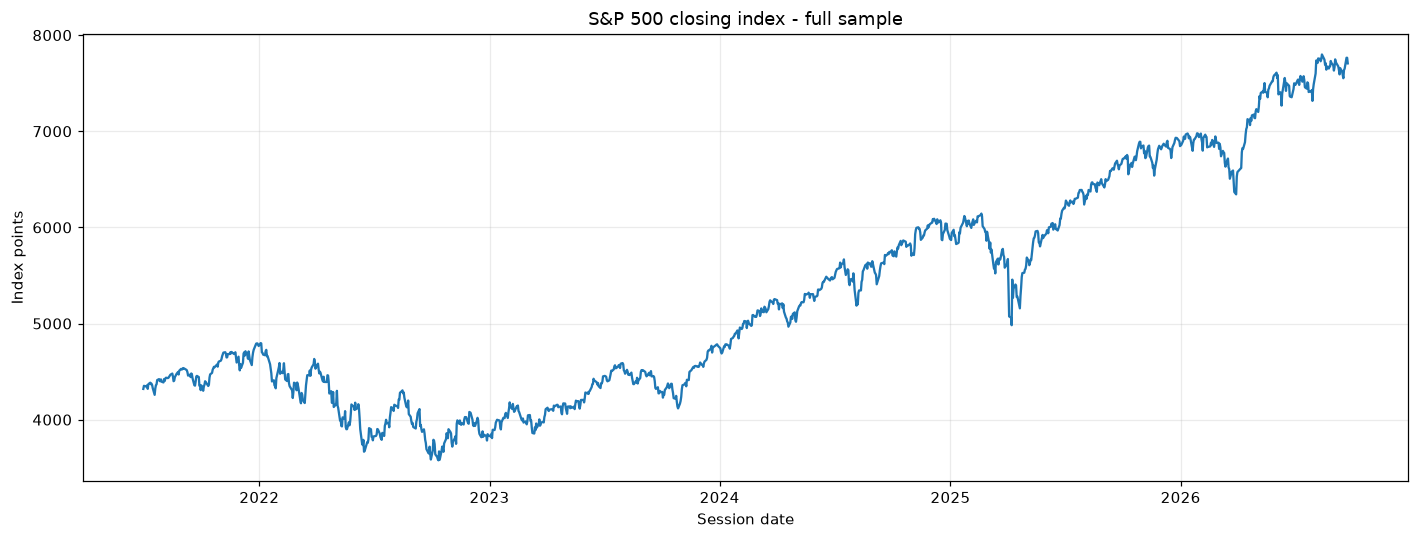

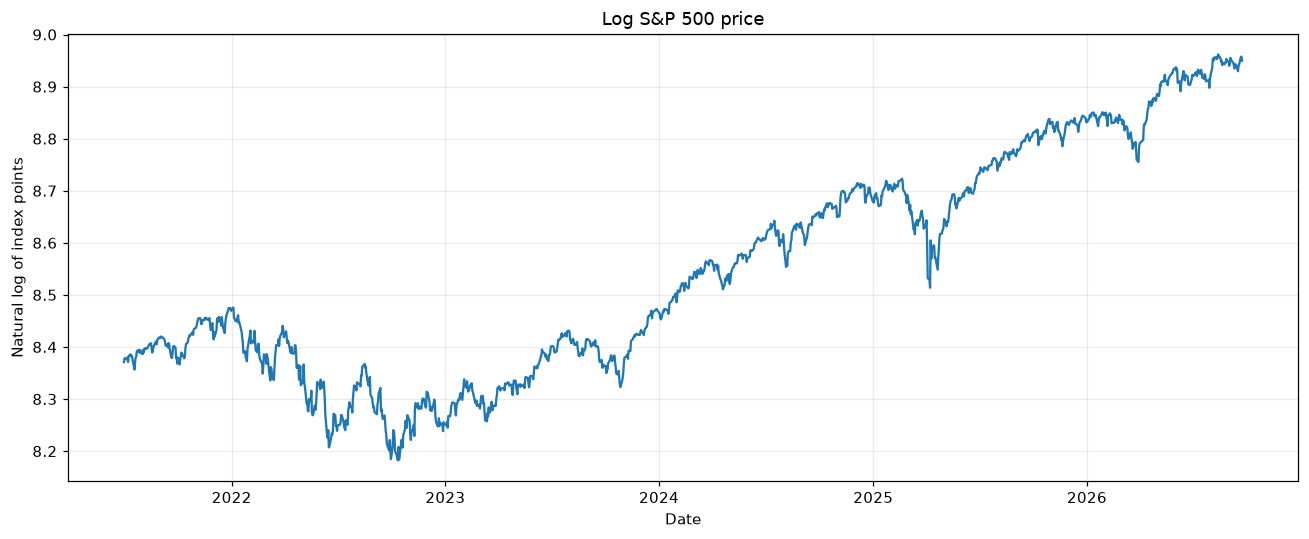

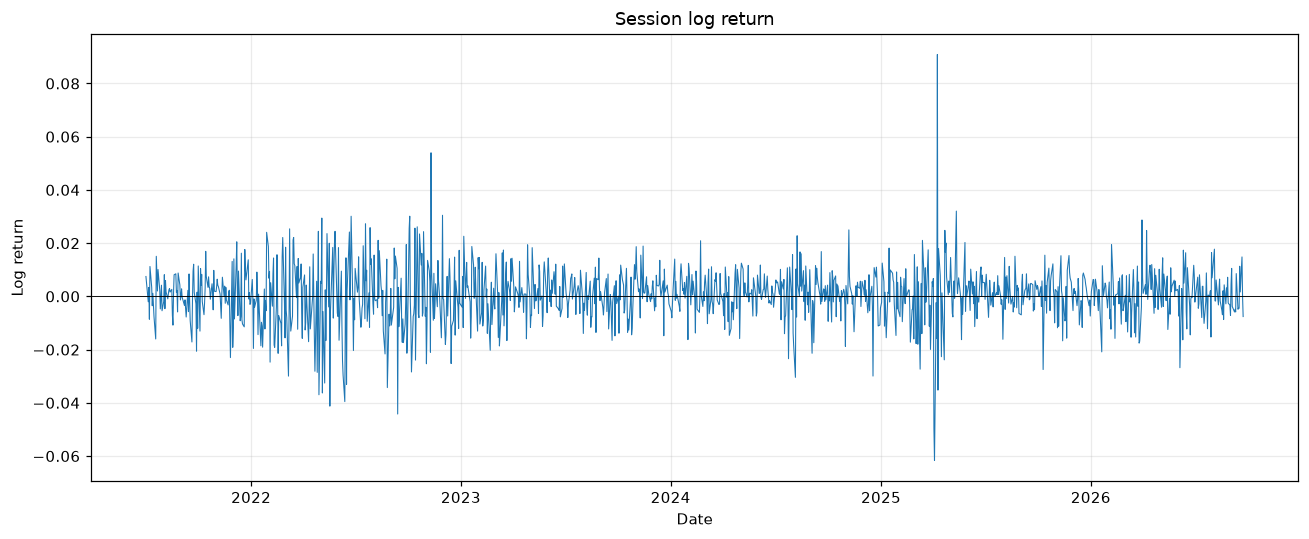

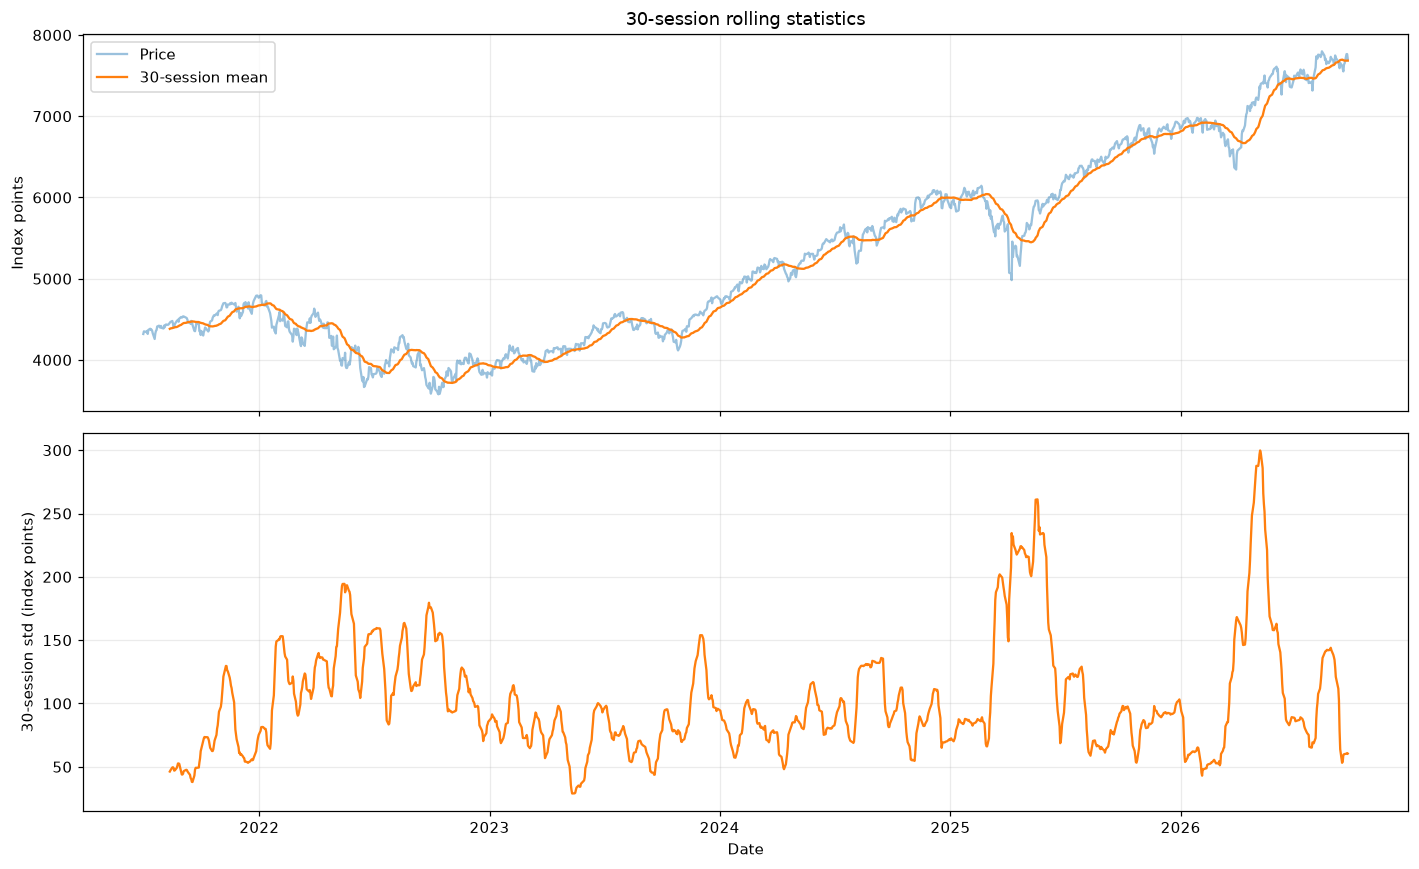

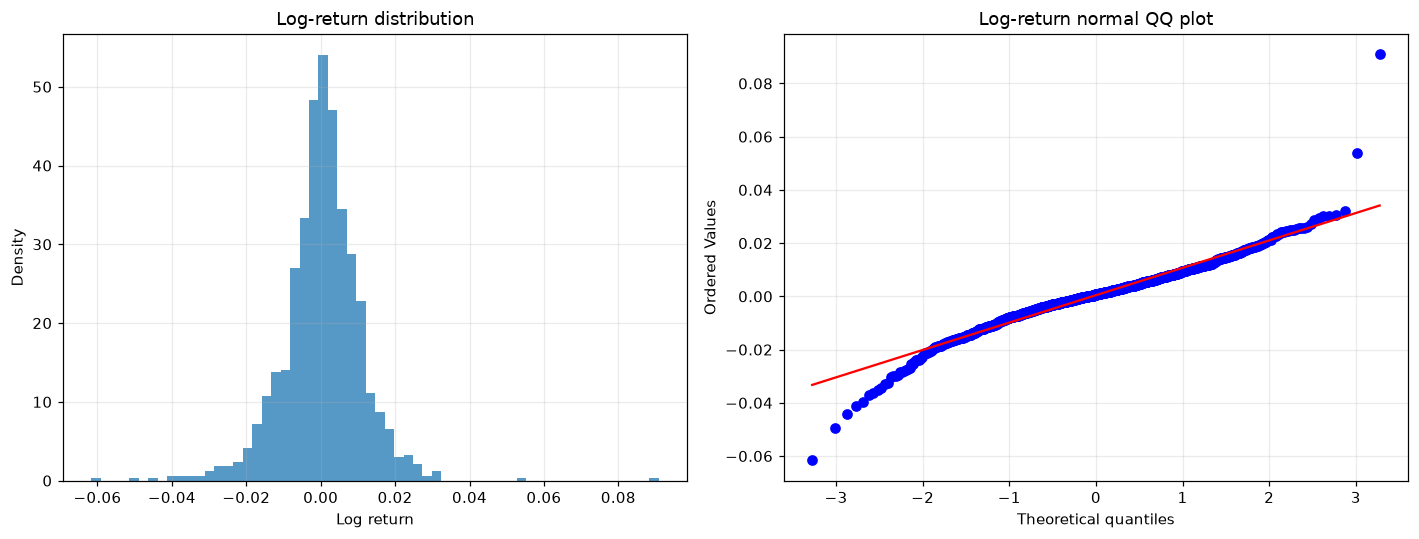

In [3]:
fig, ax = plt.subplots(figsize=(13,5))
ax.plot(df.index, df['Price'], color='tab:blue')
ax.set(title='S&P 500 closing index - full sample', ylabel='Index points', xlabel='Session date')
save_figure(fig, '01_raw_index.png')

fig, ax = plt.subplots()
ax.plot(log_price)
ax.set(title='Log S&P 500 price', ylabel='Natural log of index points', xlabel='Date')
save_figure(fig, '02_log_price.png')

log_return = log_price.diff().dropna()
fig, ax = plt.subplots()
ax.plot(log_return, linewidth=0.7)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(title='Session log return', ylabel='Log return', xlabel='Date')
save_figure(fig, '03_log_return.png')

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
axes[0].plot(df['Price'], alpha=0.45, label='Price')
axes[0].plot(df['Price'].rolling(ROLLING_WINDOW).mean(), label='30-session mean')
axes[0].set(ylabel='Index points', title='30-session rolling statistics'); axes[0].legend()
axes[1].plot(df['Price'].rolling(ROLLING_WINDOW).std(), color='tab:orange')
axes[1].set(ylabel='30-session std (index points)', xlabel='Date')
save_figure(fig, '04_rolling_stats.png')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].hist(log_return, bins=60, density=True, alpha=0.75)
axes[0].set(title='Log-return distribution', xlabel='Log return', ylabel='Density')
stats.probplot(log_return, dist='norm', plot=axes[1])
axes[1].set_title('Log-return normal QQ plot')
save_figure(fig, '05_return_distribution.png')

### Descriptive Statistics

Price and observed-step log return, reported separately for the full sample,
the first 80% (Train), and the final 20% (Test), using the notebook's raw
chronological split before scaling or windowing. Columns identify each sample;
rows give units, dates, Count, Mean, SD, Min, Q1, Median, Q3, Max, Skewness,
and Excess kurtosis.

SD uses `ddof=1`; skewness and excess kurtosis use pandas' bias-corrected
estimators (normal-distribution excess kurtosis = 0). Log returns are natural-log
changes, not percentages, across successive observed dates. The first full-sample
return is undefined and excluded. Returns belong to their ending date, so the
first Test return uses the last Train price. Calendar gaps are not filled.
Full-sample and Test statistics are descriptive reporting only, not inputs to
model selection or fitting. The tables below were calculated from the supplied
source data without rerunning model training.


In [ ]:
# Descriptive reporting only; this cell does not fit or configure a model.
def _make_descriptive_statistics(price, train_ratio):
    assert price.index.is_monotonic_increasing and price.index.is_unique
    assert price.notna().all() and np.isfinite(price).all() and price.gt(0).all()
    split = int(train_ratio * len(price))
    assert 0 < split < len(price)
    # Assign returns to their ending date; retain the Train-to-Test boundary return.
    log_return = np.log(price).diff()
    rows = []
    for variable, series, unit in [('Price', price, 'index points'),
                                    ('Log return', log_return, 'natural log; not percent')]:
        for sample, start, end in [('Full sample', 0, len(price)),
                                    ('Train', 0, split), ('Test', split, len(price))]:
            values = series.iloc[start:end].dropna()
            summary = values.describe(percentiles=[0.25, 0.5, 0.75])
            rows.append({'Variable': variable, 'Sample': sample, 'Unit': unit,
                'Start': str(values.index[0].date()), 'End': str(values.index[-1].date()),
                'Count': int(summary['count']), 'Mean': summary['mean'],
                'SD': summary['std'], 'Min': summary['min'], 'Q1': summary['25%'],
                'Median': summary['50%'], 'Q3': summary['75%'], 'Max': summary['max'],
                'Skewness': values.skew(), 'Excess kurtosis': values.kurt()})
    return pd.DataFrame(rows)

descriptive_statistics = _make_descriptive_statistics(df['Price'], TRAIN_RATIO)
del _make_descriptive_statistics
for _descriptive_variable in ['Price', 'Log return']:
    print(_descriptive_variable)
    display(descriptive_statistics.loc[
        descriptive_statistics['Variable'].eq(_descriptive_variable)
    ].drop(columns='Variable').set_index('Sample').T)
del _descriptive_variable


Price


Sample,Full sample,Train,Test
Unit,index points,index points,index points
Start,2021-07-01,2021-07-01,2025-09-08
End,2026-09-23,2025-09-05,2026-09-23
Count,1313,1050,263
Mean,5266.721813,4812.506895,7080.127376
SD,1151.885882,768.299998,391.319242
Min,3577.03,3577.03,6343.72
Q1,4328.87,4179.7775,6773.155
Median,4975.51,4538.295,6929.94
Q3,6074.08,5501.4375,7465.24


Log return


Sample,Full sample,Train,Test
Unit,natural log; not percent,natural log; not percent,natural log; not percent
Start,2021-07-02,2021-07-02,2025-09-08
End,2026-09-23,2025-09-05,2026-09-23
Count,1312,1049,263
Mean,0.000441,0.000387,0.000658
SD,0.010572,0.011119,0.00804
Min,-0.061609,-0.061609,-0.027486
Q1,-0.00472,-0.00506,-0.003815
Median,0.000731,0.000721,0.000759
Q3,0.006177,0.006369,0.005774


## Step 3 - Raw chronological Train 80% / Test 20% split

,split,start_date,end_date,n_sessions,min,max,mean
0,Train,2021-07-01,2025-09-05,1050,3577.03,6502.08,4812.506895
1,Test,2025-09-08,2026-09-23,263,6343.72,7798.99,7080.127376


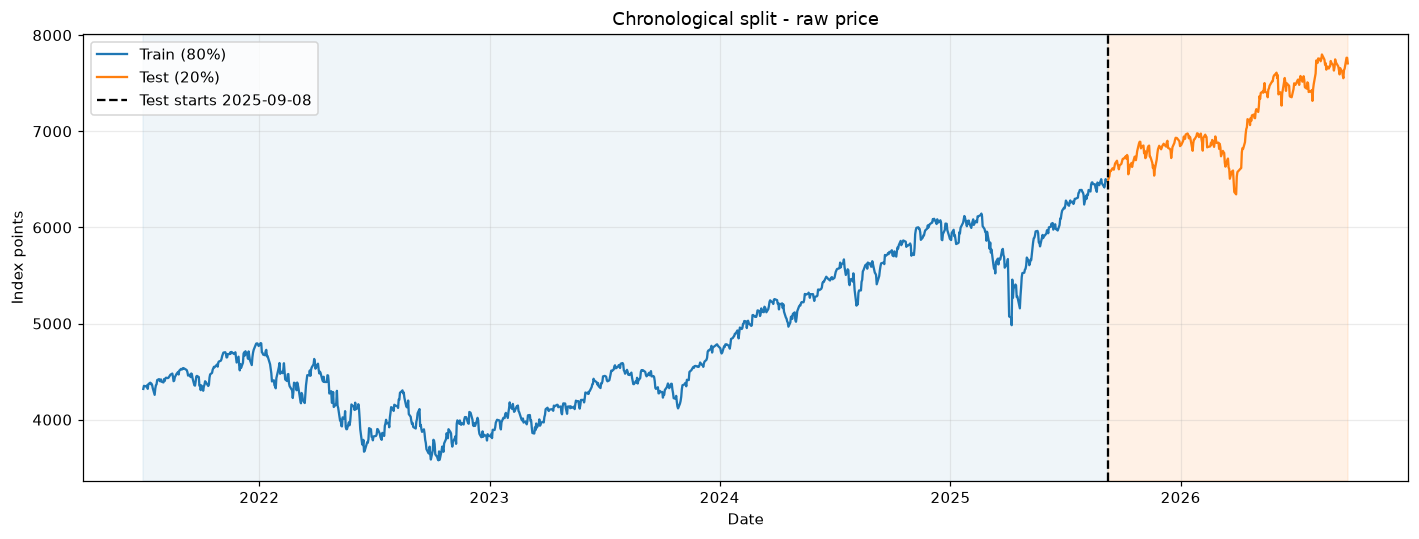

In [4]:
n = len(df)
n_train = int(TRAIN_RATIO * n)
n_test = n - n_train
train_price = df['Price'].iloc[:n_train].copy()
test_price = df['Price'].iloc[n_train:].copy()
train_log = log_price.iloc[:n_train].copy()
train_model_log = model_history(train_log)
assert n_train + n_test == n and n_test >= max(HORIZONS)
assert train_log.index[-1] < test_price.index[0]
split_summary = pd.DataFrame([dict(split=name, start_date=x.index[0].date(),
    end_date=x.index[-1].date(), n_sessions=len(x), min=x.min(), max=x.max(), mean=x.mean())
    for name, x in [('Train', train_price), ('Test', test_price)]])
save_table(split_summary, 'split_summary.csv')
display(split_summary)
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(train_price, label='Train (80%)', color='tab:blue')
ax.plot(test_price, label='Test (20%)', color='tab:orange')
ax.axvspan(df.index[0], test_price.index[0], color='tab:blue', alpha=0.07)
ax.axvspan(test_price.index[0], df.index[-1], color='tab:orange', alpha=0.10)
ax.axvline(test_price.index[0], color='black', linestyle='--', label=f'Test starts {test_price.index[0].date()}')
ax.set(title='Chronological split - raw price', ylabel='Index points', xlabel='Date')
ax.legend()
save_figure(fig, '06_train_test_split.png')

## Step 4 - Train-only stationarity and differencing

ADF H0: nonstationary (reject if p < 0.05). KPSS H0: stationary (fail to reject if p > 0.05). Start at log levels, then sequential differences up to configured MAX_D; choose the smallest d supported by both tests. Preserve bounded KPSS p-value warnings. No Test observations enter these tests.

In [5]:
stationarity_rows = []
d = None
for order in range(MAX_D+1):
    values = train_log.copy()
    for _ in range(order):
        values = values.diff().dropna()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        adf = adfuller(values, autolag='AIC')
    adf_ok = adf[1] < ALPHA
    stationarity_rows.append(dict(d=order, series=f'log_index_diff_{order}', test='ADF',
        statistic=adf[0], p_value=adf[1], stationary=adf_ok, critical_values=json.dumps(adf[4]),
        conclusion='reject nonstationarity' if adf_ok else 'fail to reject nonstationarity', warnings=warning_text(caught)))
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        kp = kpss(values, regression='c', nlags='auto')
    kp_ok = kp[1] > ALPHA
    stationarity_rows.append(dict(d=order, series=f'log_index_diff_{order}', test='KPSS',
        statistic=kp[0], p_value=kp[1], stationary=kp_ok, critical_values=json.dumps(kp[3]),
        conclusion='fail to reject stationarity' if kp_ok else 'reject stationarity', warnings=warning_text(caught)))
    if adf_ok and kp_ok:
        d, train_diff = order, values
        break
stationarity_tests = pd.DataFrame(stationarity_rows)
save_table(stationarity_tests, 'stationarity_tests.csv')
display(stationarity_tests)
assert d is not None, 'Train tests do not jointly support d <= MAX_D; stop without using Test'
TREND_OPTIONS = ['n','c'] if d==0 else (['n','t'] if d==1 else ['n'])
print('Smallest Train-supported d:', d, '; valid grid trends:', TREND_OPTIONS)

,d,series,test,statistic,p_value,stationary,critical_values,conclusion,warnings
0,0,log_index_diff_0,ADF,-0.378929,0.913558,False,"{""1%"": -3.4365991650067502, ""5%"": -2.864299173...",fail to reject nonstationarity,adfuller currently returns a plain tuple whose...
1,0,log_index_diff_0,KPSS,4.031975,0.010000,False,"{""10%"": 0.347, ""5%"": 0.463, ""2.5%"": 0.574, ""1%...",reject stationarity,The test statistic is outside of the range of ...
2,1,log_index_diff_1,ADF,-19.983946,0.000000,True,"{""1%"": -3.436617132314828, ""5%"": -2.8643070978...",reject nonstationarity,adfuller currently returns a plain tuple whose...
3,1,log_index_diff_1,KPSS,0.188206,0.100000,True,"{""10%"": 0.347, ""5%"": 0.463, ""2.5%"": 0.574, ""1%...",fail to reject stationarity,The test statistic is outside of the range of ...


Smallest Train-supported d: 1 ; valid grid trends: ['n', 't']


## Step 5 - Train-only identification and AIC shortlist

Reference grid p,q = 0..5; differencing is chosen above from Train. Trend options respect d: no trend/constant at d=0, no drift/drift at d=1, no trend at d>=2. Record every fit's AIC/BIC, convergence, warnings and errors. Inspect the configured top three converged finite-AIC candidates; Test is not accessed.

The pmdarima full-grid cross-check is supplementary, with `max_order=None` and explicit intercept variants where admissible. It does not replace the predeclared statsmodels selection rule.

**AIC Rank:** อันดับเริ่มจาก 1 เฉพาะโมเดลที่ converged, AIC finite และไม่มี fit error เรียง AIC จากน้อยไปมาก แล้วใช้ BIC และชื่อโมเดลเมื่อค่าเท่ากัน ตารางด้านล่างแสดง **Top 5** เพื่อเปรียบเทียบ โดยยังใช้ **Top 3** สำหรับการเลือกโมเดลใน Step 6 ตามกติกาเดิมของ notebook นี้ ไม่เปลี่ยนผลพยากรณ์


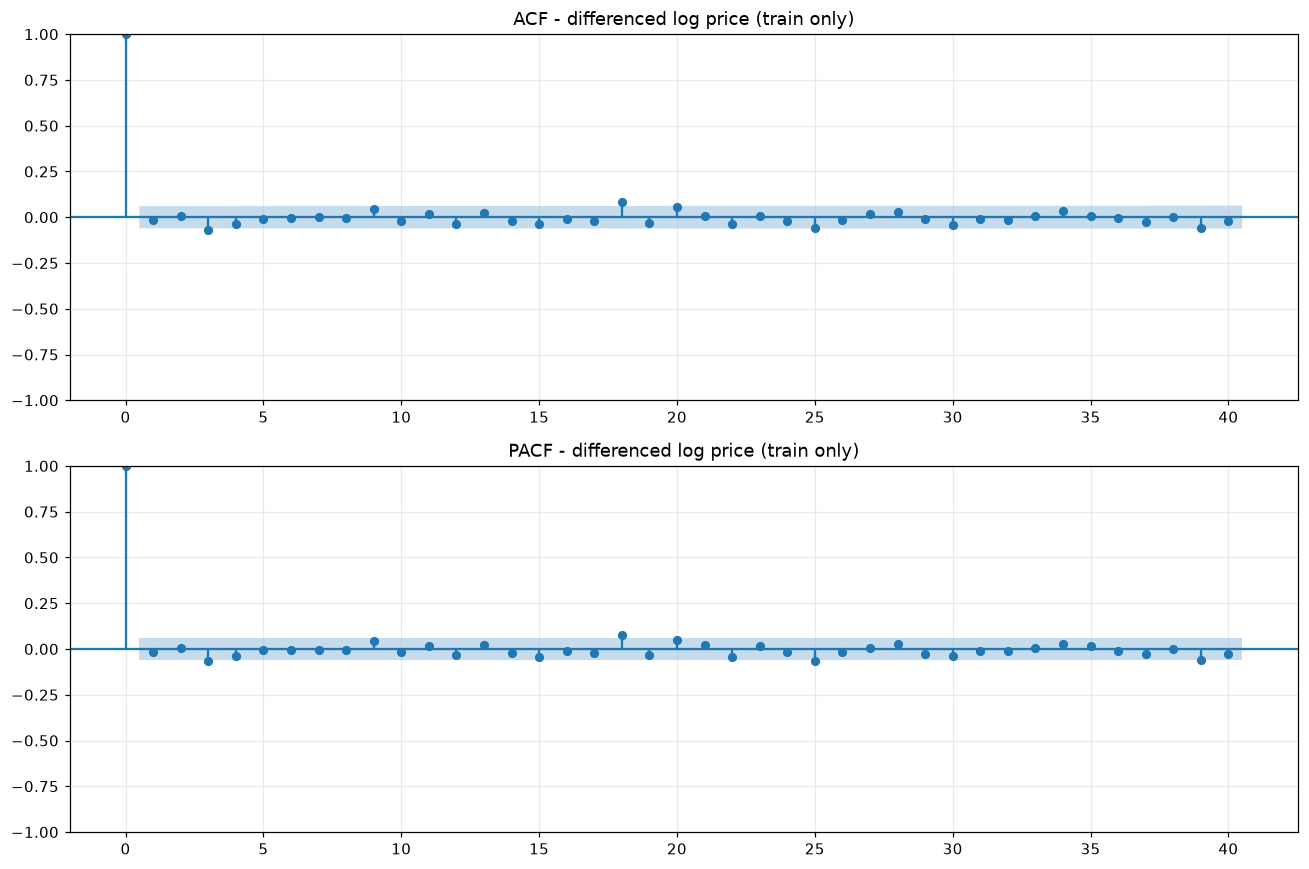

Grid progress: p=0, 12/72 fits completed


Grid progress: p=1, 24/72 fits completed


Grid progress: p=2, 36/72 fits completed


Grid progress: p=3, 48/72 fits completed


Grid progress: p=4, 60/72 fits completed


Grid progress: p=5, 72/72 fits completed


AIC Rank,model,p,d,q,trend,AIC,BIC,converged,warnings,error
1,"ARIMA(0,1,0), trend=t",0,1,0,t,-6459.1987,-6449.2875,True,,
2,"ARIMA(0,1,3), trend=n",0,1,3,n,-6458.8840,-6439.0617,True,,
3,"ARIMA(3,1,0), trend=n",3,1,0,n,-6458.7261,-6438.9037,True,,
4,"ARIMA(0,1,3), trend=t",0,1,3,t,-6458.3962,-6433.6182,True,,
5,"ARIMA(0,1,4), trend=n",0,1,4,n,-6458.3140,-6433.5360,True,,


In [6]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))
plot_acf(train_diff, lags=40, ax=axes[0])
plot_pacf(train_diff, lags=40, method='ywm', ax=axes[1])
axes[0].set_title('ACF - differenced log price (train only)')
axes[1].set_title('PACF - differenced log price (train only)')
save_figure(fig, '07_acf_pacf.png')

grid_rows, fitted_models = [], {}
for p in range(MAX_P + 1):
    for q in range(MAX_Q + 1):
        for trend in TREND_OPTIONS:
            label = f'ARIMA({p},{d},{q}), trend={trend}'
            row = dict(model=label, p=p, d=d, q=q, trend=trend, AIC=np.nan,
                       BIC=np.nan, converged=False, warnings='', error='')
            caught = []
            try:
                with warnings.catch_warnings(record=True) as caught:
                    warnings.simplefilter('always')
                    result = ARIMA(train_model_log, order=(p, d, q), trend=trend).fit()
                row.update(AIC=result.aic, BIC=result.bic,
                           converged=bool(result.mle_retvals.get('converged', False)))
                fitted_models[label] = result
            except Exception as exc:
                row['error'] = f'{type(exc).__name__}: {exc}'
            row['warnings'] = warning_text(caught)
            grid_rows.append(row)
    print(f'Grid progress: p={p}, {len(grid_rows)}/{(MAX_P+1)*(MAX_Q+1)*len(TREND_OPTIONS)} fits completed', flush=True)
grid_search = pd.DataFrame(grid_rows).sort_values(['AIC', 'BIC', 'model'], na_position='last').reset_index(drop=True)
# Sequential AIC ranks among converged, finite-AIC, error-free Train fits.
eligible_mask = grid_search['converged'] & np.isfinite(grid_search['AIC']) & grid_search['error'].eq('')
grid_search.insert(0, 'AIC Rank', pd.Series(pd.NA, index=grid_search.index, dtype='Int64'))
grid_search.loc[eligible_mask, 'AIC Rank'] = np.arange(1, int(eligible_mask.sum()) + 1)
save_table(grid_search, 'grid_search_aic_bic.csv')
eligible = grid_search.loc[eligible_mask].copy()
assert len(eligible) >= TOP_K, 'Fewer than three converged grid candidates; inspect grid_search_aic_bic.csv'
candidates = eligible.head(TOP_K).copy()
save_table(candidates, 'top3_candidates.csv')
# Show Top 5 for comparison; the original Top 3 selection is unchanged.
aic_rank_preview = eligible.head(5).copy()
display(aic_rank_preview.style.format({'AIC': '{:.4f}', 'BIC': '{:.4f}'}).hide(axis='index'))

In [7]:
cross_rows = []
for intercept in ([False, True] if d <= 1 else [False]):
    caught = []
    row = dict(with_intercept=intercept, order='', AIC=np.nan, BIC=np.nan,
               converged=False, warnings='', error='')
    try:
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            cross = pm.auto_arima(train_model_log, d=d, seasonal=False, stepwise=False,
                information_criterion='aic', start_p=0, start_q=0,
                max_p=MAX_P, max_q=MAX_Q, max_order=None, with_intercept=intercept,
                suppress_warnings=False, error_action='warn', n_jobs=1)
        row.update(order=str(cross.order), AIC=cross.aic(), BIC=cross.bic(),
                   converged=bool(cross.arima_res_.mle_retvals.get('converged', False)))
    except Exception as exc:
        row['error'] = f'{type(exc).__name__}: {exc}'
    row['warnings'] = warning_text(caught)
    cross_rows.append(row)
    print(f'auto_arima cross-check complete: with_intercept={intercept}', flush=True)
cross_check = pd.DataFrame(cross_rows)
save_table(cross_check, 'auto_arima_cross_check.csv')
display(cross_check)
assert cross_check['error'].eq('').all(), 'auto_arima cross-check failed; inspect saved errors'

auto_arima cross-check complete: with_intercept=False


auto_arima cross-check complete: with_intercept=True


,with_intercept,order,AIC,BIC,converged,warnings,error
0,False,"(0, 1, 0)",-6459.92907,-6454.973477,False,Maximum Likelihood optimization failed to conv...,
1,True,"(0, 1, 0)",-6459.19920,-6449.288014,False,Maximum Likelihood optimization failed to conv...,


## Step 6 - Train residual diagnostics and final model

Remove the fitted model's initialization burn-in (at least d observations). Selection gates: Ljung-Box p > 0.05 at lags 10/20/30 with model_df=p+q, and existing AR/MA roots strictly outside the unit circle. Among the AIC shortlist choose the lowest-AIC model satisfying both. Stop if none qualifies; no Test-based fallback.

Residual mean, ARCH, Jarque-Bera and parameter significance are reporting only. Missing roots are N/A. Robust covariance, when needed for ARCH reporting, is fitted on Train separately; forecasts retain the original selected parameters. Significant ARCH/non-normality may impair model-based interval coverage.

C:\Users\User\anaconda3\envs\vs_nine_tf\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


C:\Users\User\anaconda3\envs\vs_nine_tf\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


C:\Users\User\anaconda3\envs\vs_nine_tf\Lib\site-packages\statsmodels\stats\diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(


,model,AIC,ljung_box_pass,roots_pass,arch_pvalue
0,"ARIMA(0,1,0), trend=t",-6459.198715,True,True,1.494353e-25
1,"ARIMA(0,1,3), trend=n",-6458.884046,True,True,3.178866e-28
2,"ARIMA(3,1,0), trend=n",-6458.726058,True,True,3.746346e-28


,model,test,statistic,p_value,pass_fail,note
0,"ARIMA(0,1,0), trend=t",Ljung-Box lag 10,9.048196,5.275358e-01,PASS,model_df=0
1,"ARIMA(0,1,0), trend=t",Ljung-Box lag 20,26.129981,1.615618e-01,PASS,model_df=0
2,"ARIMA(0,1,0), trend=t",Ljung-Box lag 30,35.911050,2.110040e-01,PASS,model_df=0
3,"ARIMA(0,1,0), trend=t",Mean = 0 (t-test),0.014357,9.885478e-01,PASS,Residual mean=4.92881e-06
4,"ARIMA(0,1,0), trend=t",ARCH LM (10 lags),142.196340,1.494353e-25,FAIL,
5,"ARIMA(0,1,0), trend=t",Jarque-Bera,1762.599924,0.000000e+00,FAIL,"skew=0.0517, kurtosis=9.3495"
6,"ARIMA(0,1,0), trend=t",AR roots outside unit circle,NaN,NaN,REPORTED,N/A: no roots
7,"ARIMA(0,1,0), trend=t",MA roots outside unit circle,NaN,NaN,REPORTED,N/A: no roots
8,"ARIMA(0,1,0), trend=t",Parameter significance: x1,0.000382,2.655286e-01,FAIL,"Report only; estimate in statistic column, sig..."
9,"ARIMA(0,1,0), trend=t",Parameter significance: sigma2,0.000123,0.000000e+00,PASS,"Report only; estimate in statistic column, sig..."


Selected: ARIMA(0,1,0), trend=t


,model,parameter,estimate,standard_error,p_value,significant,covariance
0,"ARIMA(0,1,0), trend=t",x1,0.000382,0.000343,0.265529,False,opg
1,"ARIMA(0,1,0), trend=t",sigma2,0.000123,0.000003,0.000000,True,opg


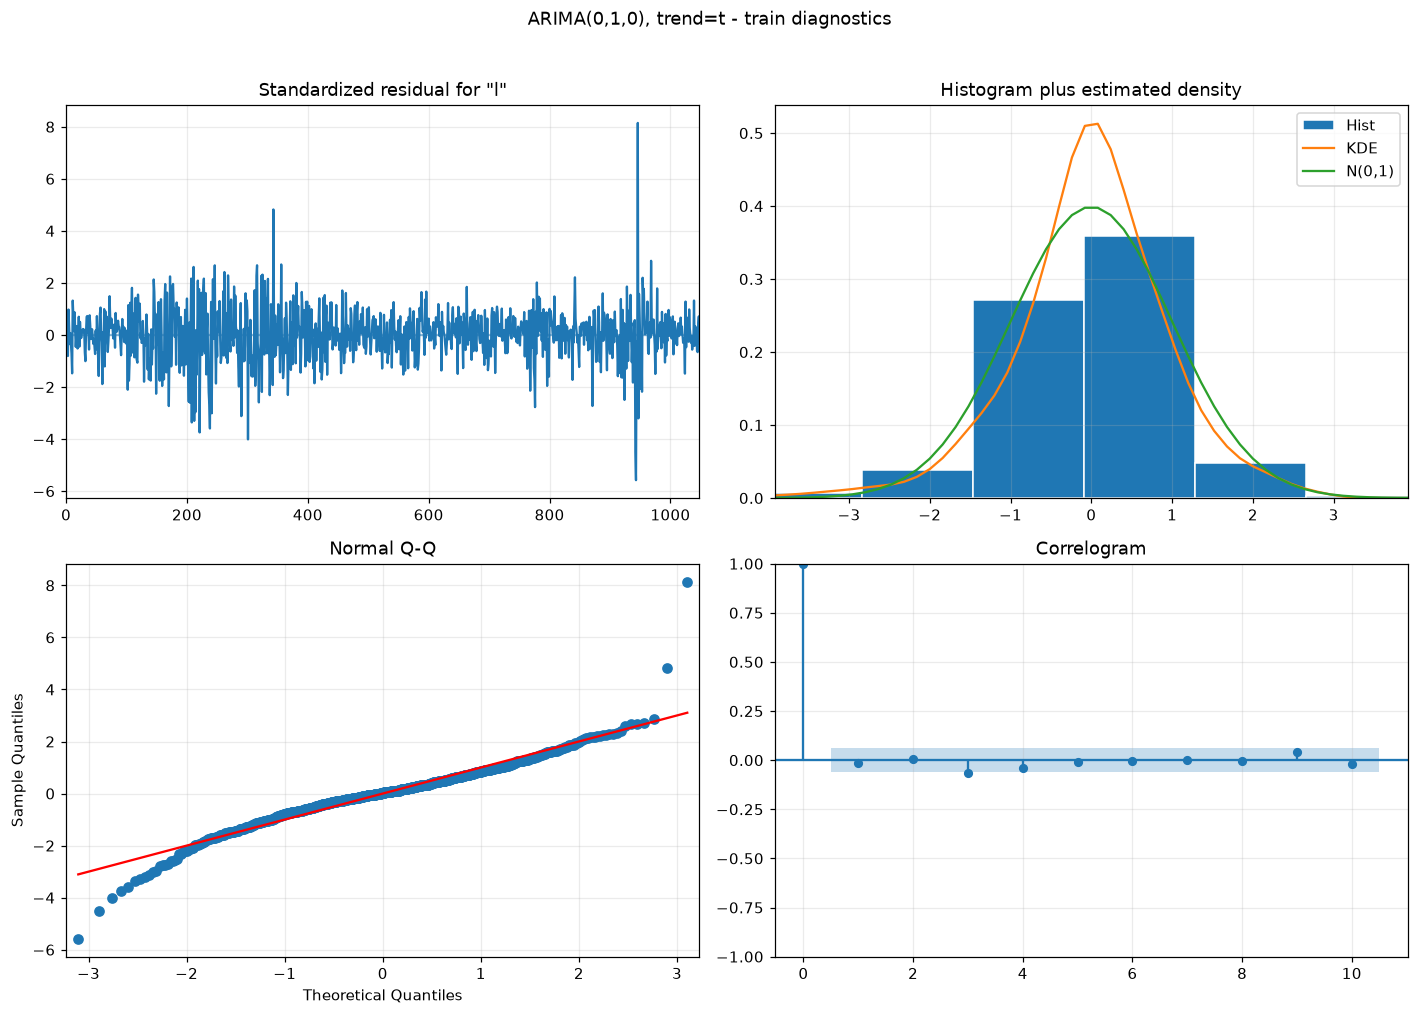

,model,parameter,estimate,robust_standard_error,robust_p_value,converged,warnings
0,"ARIMA(0,1,0), trend=t",x1,0.000382,0.000343,2.657980e-01,True,
1,"ARIMA(0,1,0), trend=t",sigma2,0.000123,0.000011,4.052043e-29,True,


                               SARIMAX Results                                
Dep. Variable:              log_index   No. Observations:                 1050
Model:                 ARIMA(0, 1, 0)   Log Likelihood                3231.599
Date:                Sat, 10 Oct 2026   AIC                          -6459.199
Time:                        18:34:33   BIC                          -6449.288
Sample:                             0   HQIC                         -6455.441
                               - 1050                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
x1             0.0004      0.000      1.113      0.266      -0.000       0.001
sigma2         0.0001   2.64e-06     46.820      0.000       0.000       0.000
Ljung-Box (L1) (Q):                   0.24   Jarque-

In [8]:
check_rows, parameter_rows, root_rows, candidate_status = [], [], [], []
robust_results, robust_rows, robust_warning_messages = {}, [], {}
def add_check(model, test, statistic=np.nan, p_value=np.nan, passed=None, note=''):
    check_rows.append(dict(model=model, test=test, statistic=statistic, p_value=p_value,
                           pass_fail='REPORTED' if passed is None else ('PASS' if passed else 'FAIL'), note=note))

for item in candidates.itertuples(index=False):
    result = fitted_models[item.model]
    burn_in = max(d, int(result.loglikelihood_burn))
    residuals = pd.Series(np.asarray(result.resid)[burn_in:]).dropna()
    assert min(LB_LAGS) > item.p + item.q and len(residuals) > max(LB_LAGS)
    lb = acorr_ljungbox(residuals, lags=LB_LAGS, model_df=item.p + item.q, return_df=True)
    lb_pass = bool(lb['lb_pvalue'].notna().all() and (lb['lb_pvalue'] > ALPHA).all())
    for lag, row in lb.iterrows():
        add_check(item.model, f'Ljung-Box lag {lag}', row['lb_stat'], row['lb_pvalue'],
                  bool(row['lb_pvalue'] > ALPHA), f'model_df={item.p + item.q}')
    mean_stat, mean_p = stats.ttest_1samp(residuals, 0)
    add_check(item.model, 'Mean = 0 (t-test)', mean_stat, mean_p, mean_p > ALPHA,
              f'Residual mean={residuals.mean():.6g}')
    arch_stat, arch_p, _, _ = het_arch(residuals, nlags=10)
    add_check(item.model, 'ARCH LM (10 lags)', arch_stat, arch_p, arch_p > ALPHA)
    if arch_p <= ALPHA:
        with warnings.catch_warnings(record=True) as robust_caught:
            warnings.simplefilter('always')
            robust = ARIMA(train_model_log, order=(item.p, d, item.q), trend=item.trend).fit(cov_type='robust')
        robust_results[item.model] = robust
        robust_warning_messages[item.model] = warning_text(robust_caught)
        for name, coef, se, pv in zip(robust.param_names, robust.params, robust.bse, robust.pvalues):
            robust_rows.append(dict(model=item.model, parameter=name, estimate=coef,
                robust_standard_error=se, robust_p_value=pv,
                converged=bool(robust.mle_retvals.get('converged', False)),
                warnings=warning_text(robust_caught)))
    jb_stat, jb_p, skew, kurt = jarque_bera(residuals)
    add_check(item.model, 'Jarque-Bera', jb_stat, jb_p, jb_p > ALPHA,
              f'skew={skew:.4f}, kurtosis={kurt:.4f}')
    roots_pass = True
    for kind, roots in [('AR', result.arroots), ('MA', result.maroots)]:
        moduli = np.abs(roots)
        passed = bool((moduli > 1).all())
        roots_pass &= passed
        add_check(item.model, f'{kind} roots outside unit circle',
                  moduli.min() if len(moduli) else np.nan, passed=passed if len(moduli) else None,
                  note='N/A: no roots' if not len(moduli) else f'All |root|>1: {passed}')
        for j, root in enumerate(roots, 1):
            root_rows.append(dict(model=item.model, kind=kind, root_number=j,
                                  real=root.real, imag=root.imag, modulus=abs(root), outside=abs(root) > 1))
    for name, coef, se, pv in zip(result.param_names, result.params, result.bse, result.pvalues):
        parameter_rows.append(dict(model=item.model, parameter=name, estimate=coef, standard_error=se,
                                   p_value=pv, significant=pv < ALPHA, covariance=result.cov_type))
        add_check(item.model, f'Parameter significance: {name}', coef, pv, pv < ALPHA,
                  'Report only; estimate in statistic column, significance uses p < alpha')
    candidate_status.append(dict(model=item.model, AIC=item.AIC, ljung_box_pass=lb_pass,
                                 roots_pass=roots_pass, arch_pvalue=arch_p))

assumption_checks = pd.DataFrame(check_rows)
parameter_significance = pd.DataFrame(parameter_rows)
candidate_diagnostics = pd.DataFrame(candidate_status).sort_values('AIC')
save_table(assumption_checks, 'assumption_checks.csv')
save_table(parameter_significance, 'parameter_significance.csv')
save_table(pd.DataFrame(root_rows, columns=['model','kind','root_number','real','imag','modulus','outside']), 'model_roots.csv')
save_table(candidate_diagnostics, 'candidate_diagnostics.csv')
if robust_rows:
    save_table(pd.DataFrame(robust_rows), 'robust_parameter_significance.csv')
display(candidate_diagnostics)
display(assumption_checks)
passing = candidate_diagnostics.loc[candidate_diagnostics['ljung_box_pass'] & candidate_diagnostics['roots_pass']]
assert not passing.empty, 'No top-3 candidate passes Ljung-Box and roots. Review train-only diagnostics; do not relax using test.'
final_label = passing.iloc[0]['model']
final_spec = candidates.set_index('model').loc[final_label]
res = fitted_models[final_label]  # reuse original train fit; frozen forecast parameters
frozen_params = np.asarray(res.params).copy()
assert res.nobs == n_train
print('Selected:', final_label)
display(parameter_significance.loc[parameter_significance['model'].eq(final_label)])
fig = res.plot_diagnostics(figsize=(13, 9))
fig.suptitle(f'{final_label} - train diagnostics', y=1.02)
save_figure(fig, '08_residual_diagnostics.png')

summary_text = res.summary().as_text()
robust_res = None
if passing.iloc[0]['arch_pvalue'] <= ALPHA:
    robust_res = robust_results[final_label]
    display(pd.DataFrame(robust_rows).loc[lambda x: x['model'].eq(final_label)])
    summary_text += '\n\nROBUST COVARIANCE REFIT ON TRAIN - reporting only; forecasts retain original parameters.\n'
    summary_text += robust_res.summary().as_text()
    summary_text += '\nWarnings: ' + robust_warning_messages[final_label]
    summary_text += '\nRobust refit converged: ' + str(robust_res.mle_retvals.get('converged', False))
assert np.array_equal(np.asarray(res.params), frozen_params)
print(summary_text)

## Step 7 - Forecast values by horizon

`arima_fc`, `arima_lo95`, `arima_hi95` are in index points. The exponentiated log forecast mean is a conditional median, not a bias-corrected arithmetic mean. Bounds are model-based 95% prediction intervals, not guaranteed coverage.

### 7.1 Historical rolling-origin forecasts

Start at the final Train session and advance one observed session at a time. Use history only through each origin with `apply(..., refit=False)`; all forecasts from that origin are computed before later observations are available. ARIMA multi-step forecasts use its model dynamics recursively. Subsequent actuals may update the next origin's filtering state, never revise the previous forecast or refit parameters.

In [9]:
log_all = log_price
forecast_rows = []
for i in range(n_train - 1, n - 1):
    r = res.apply(model_history(log_all.iloc[:i+1]), refit=False)
    assert np.array_equal(np.asarray(r.params), frozen_params), 'Parameters changed during test'
    fc = r.get_forecast(steps=max(HORIZONS))
    means = np.asarray(fc.predicted_mean)
    ci = np.asarray(fc.conf_int(alpha=ALPHA))
    for h in HORIZONS:
        target = i + h
        if target < n:
            row = dict(origin_date=log_all.index[i], h=h, target_date=log_all.index[target],
                actual=df['Price'].iloc[target], arima_fc=np.exp(means[h-1]),
                arima_lo95=np.exp(ci[h-1, 0]), arima_hi95=np.exp(ci[h-1, 1]),
                price_origin=df['Price'].iloc[i])
            # Treat rounding noise as zero price movement, not a predicted direction.
            if np.isclose(row['arima_fc'], row['price_origin'], rtol=32*np.finfo(float).eps, atol=0):
                row['arima_fc'] = row['price_origin']
            forecast_rows.append(row)
    if (i - n_train + 2) % 50 == 0:
        print(f'Rolling origins completed: {i - n_train + 2}/{n_test}', flush=True)
forecasts = pd.DataFrame(forecast_rows).sort_values(['h', 'target_date']).reset_index(drop=True)
counts = forecasts.groupby('h').size()
for h in HORIZONS:
    assert counts[h] == n_test - h + 1, (h, counts[h])
assert (forecasts['target_date'] >= test_price.index[0]).all()
assert (df.index.get_indexer(forecasts['target_date']) - df.index.get_indexer(forecasts['origin_date']) == forecasts['h'].to_numpy()).all()
assert (forecasts['arima_fc'] > 0).all() and (forecasts['actual'] > 0).all()
assert (forecasts['arima_lo95'] <= forecasts['arima_fc']).all() and (forecasts['arima_fc'] <= forecasts['arima_hi95']).all()
assert not forecasts.duplicated(['origin_date', 'h']).any()
assert np.isfinite(forecasts.select_dtypes('number').to_numpy()).all()
assert (forecasts['arima_lo95'] <= forecasts['arima_hi95']).all()
save_table(forecasts, 'forecasts_long.csv')
display(counts.rename('n_points').to_frame())

Rolling origins completed: 50/263


Rolling origins completed: 100/263


Rolling origins completed: 150/263


Rolling origins completed: 200/263


Rolling origins completed: 250/263


,n_points
h,
1,263
3,261
5,259
7,257
14,250
21,243
30,234


### 7.2 Full historical Test forecast tables by horizon

Every row is retained below in a scrollable table: origin, target, origin index, actual, forecast and 95% interval, in index points. These target dates are entirely inside Test; no external files are created.

In [10]:
forecast_columns = ['origin_date','target_date','price_origin','actual','arima_fc','arima_lo95','arima_hi95']
for h in HORIZONS:
    horizon_forecasts = forecasts.loc[forecasts.h.eq(h), forecast_columns].copy()
    save_table(horizon_forecasts, f'forecasts_h{h}.csv')
    display(Markdown(f'**Test forecasts: h={h} trading sessions ({len(horizon_forecasts)} rows)**'))
    show_scroll_table(horizon_forecasts)

**Test forecasts: h=1 trading sessions (263 rows)**

origin_date,target_date,price_origin,actual,arima_fc,arima_lo95,arima_hi95
2025-09-05,2025-09-08,"6,481.5000","6,495.1500","6,483.9754","6,344.3173","6,626.7077"
2025-09-08,2025-09-09,"6,495.1500","6,512.6100","6,497.6306","6,357.6784","6,640.6635"
2025-09-09,2025-09-10,"6,512.6100","6,532.0400","6,515.0972","6,374.7689","6,658.5147"
2025-09-10,2025-09-11,"6,532.0400","6,587.4700","6,534.5347","6,393.7876","6,678.3800"
2025-09-11,2025-09-12,"6,587.4700","6,584.2900","6,589.9858","6,448.0444","6,735.0518"
2025-09-12,2025-09-15,"6,584.2900","6,615.2800","6,586.8046","6,444.9317","6,731.8006"
2025-09-15,2025-09-16,"6,615.2800","6,606.7600","6,617.8065","6,475.2658","6,763.4848"
2025-09-16,2025-09-17,"6,606.7600","6,600.3500","6,609.2832","6,466.9262","6,754.7740"
2025-09-17,2025-09-18,"6,600.3500","6,631.9600","6,602.8708","6,460.6518","6,748.2204"
2025-09-18,2025-09-19,"6,631.9600","6,664.3600","6,634.4928","6,491.5928","6,780.5385"


**Test forecasts: h=3 trading sessions (261 rows)**

origin_date,target_date,price_origin,actual,arima_fc,arima_lo95,arima_hi95
2025-09-05,2025-09-10,"6,481.5000","6,532.0400","6,488.9289","6,248.7615","6,738.3270"
2025-09-08,2025-09-11,"6,495.1500","6,587.4700","6,502.5946","6,261.9214","6,752.5179"
2025-09-09,2025-09-12,"6,512.6100","6,584.2900","6,520.0746","6,278.7544","6,770.6698"
2025-09-10,2025-09-15,"6,532.0400","6,615.2800","6,539.5269","6,297.4867","6,790.8697"
2025-09-11,2025-09-16,"6,587.4700","6,606.7600","6,595.0204","6,350.9263","6,848.4961"
2025-09-12,2025-09-17,"6,584.2900","6,600.3500","6,591.8367","6,347.8605","6,845.1901"
2025-09-15,2025-09-18,"6,615.2800","6,631.9600","6,622.8623","6,377.7377","6,877.4080"
2025-09-16,2025-09-19,"6,606.7600","6,664.3600","6,614.3325","6,369.5236","6,868.5504"
2025-09-17,2025-09-22,"6,600.3500","6,693.7500","6,607.9152","6,363.3438","6,861.8864"
2025-09-18,2025-09-23,"6,631.9600","6,656.9200","6,639.5614","6,393.8188","6,894.7490"


**Test forecasts: h=5 trading sessions (259 rows)**

...

origin_date,target_date,price_origin,actual,arima_fc,arima_lo95,arima_hi95
2025-09-05,2025-09-25,"6,481.5000","6,604.7200","6,516.2413","6,006.4010","7,069.3582"
2025-09-08,2025-09-26,"6,495.1500","6,643.7000","6,529.9644","6,019.0504","7,084.2462"
2025-09-09,2025-09-29,"6,512.6100","6,661.2100","6,547.5180","6,035.2306","7,103.2898"
2025-09-10,2025-09-30,"6,532.0400","6,688.4600","6,567.0522","6,053.2364","7,124.4821"
2025-09-11,2025-10-01,"6,587.4700","6,711.2000","6,622.7793","6,104.6033","7,184.9394"
2025-09-12,2025-10-02,"6,584.2900","6,715.3500","6,619.5822","6,101.6564","7,181.4710"
2025-09-15,2025-10-03,"6,615.2800","6,715.7900","6,650.7383","6,130.3748","7,215.2717"
2025-09-16,2025-10-06,"6,606.7600","6,740.2800","6,642.1727","6,122.4793","7,205.9790"
2025-09-17,2025-10-07,"6,600.3500","6,714.5900","6,635.7283","6,116.5392","7,198.9876"
2025-09-18,2025-10-08,"6,631.9600","6,753.7200","6,667.5077","6,145.8322","7,233.4646"


**Test forecasts: h=21 trading sessions (243 rows)**

origin_date,target_date,price_origin,actual,arima_fc,arima_lo95,arima_hi95
2025-09-05,2025-10-06,"6,481.5000","6,740.2800","6,533.6816","5,913.2063","7,219.2638"
2025-09-08,2025-10-07,"6,495.1500","6,714.5900","6,547.4415","5,925.6594","7,234.4675"
2025-09-09,2025-10-08,"6,512.6100","6,753.7200","6,565.0421","5,941.5886","7,253.9149"
2025-09-10,2025-10-09,"6,532.0400","6,735.1100","6,584.6285","5,959.3149","7,275.5566"
2025-09-11,2025-10-10,"6,587.4700","6,552.5100","6,640.5048","6,009.8849","7,337.2959"
2025-09-12,2025-10-13,"6,584.2900","6,654.7200","6,637.2992","6,006.9837","7,333.7540"
2025-09-15,2025-10-14,"6,615.2800","6,644.3100","6,668.5387","6,035.2565","7,368.2714"
2025-09-16,2025-10-15,"6,606.7600","6,671.0600","6,659.9501","6,027.4835","7,358.7817"
2025-09-17,2025-10-16,"6,600.3500","6,629.0700","6,653.4885","6,021.6356","7,351.6420"
2025-09-18,2025-10-17,"6,631.9600","6,664.0100","6,685.3530","6,050.4740","7,386.8501"


**Test forecasts: h=30 trading sessions (234 rows)**

origin_date,target_date,price_origin,actual,arima_fc,arima_lo95,arima_hi95
2025-09-05,2025-10-17,"6,481.5000","6,664.0100","6,556.1736","5,819.0928","7,386.6175"
2025-09-08,2025-10-20,"6,495.1500","6,735.1300","6,569.9809","5,831.3478","7,402.1736"
2025-09-09,2025-10-21,"6,512.6100","6,735.3500","6,587.6420","5,847.0234","7,422.0719"
2025-09-10,2025-10-22,"6,532.0400","6,699.4000","6,607.2959","5,864.4676","7,444.2152"
2025-09-11,2025-10-23,"6,587.4700","6,738.4400","6,663.3645","5,914.2327","7,507.3858"
2025-09-12,2025-10-24,"6,584.2900","6,791.6900","6,660.1479","5,911.3777","7,503.7617"
2025-09-15,2025-10-27,"6,615.2800","6,875.1600","6,691.4949","5,939.2005","7,539.0793"
2025-09-16,2025-10-28,"6,606.7600","6,890.8900","6,682.8767","5,931.5513","7,529.3695"
2025-09-17,2025-10-29,"6,600.3500","6,890.5900","6,676.3929","5,925.7964","7,522.0644"
2025-09-18,2025-10-30,"6,631.9600","6,822.3400","6,708.3671","5,954.1758","7,558.0886"


### 7.3 Future forecasts from the latest observed session

All horizons share the last CSV observation as origin (not today's date). Update filtering states using observed history with the original Train parameters fixed. Target dates use subsequent NYSE sessions, excluding weekends/holidays; early-close days still count. Future rows have no actuals or RMSE/MAPE.

In [11]:
# Update filtering states with the latest observed data, keeping train parameters fixed.
latest_origin = log_all.index[-1]
latest_result = res.apply(model_history(log_all), refit=False)
assert np.array_equal(np.asarray(latest_result.params), frozen_params)
latest_fc = latest_result.get_forecast(steps=max(HORIZONS))
latest_means = np.exp(np.asarray(latest_fc.predicted_mean))
latest_ci = np.exp(np.asarray(latest_fc.conf_int(alpha=ALPHA)))
future_dates = nyse_sessions(latest_origin + pd.Timedelta(days=1), latest_origin + pd.Timedelta(days=max(HORIZONS)*3+30))[:max(HORIZONS)]
assert len(future_dates) == max(HORIZONS)
latest_price = float(df['Price'].iloc[-1])
future_rows = []
for h in HORIZONS:
    value = latest_means[h-1]
    if np.isclose(value, latest_price, rtol=32*np.finfo(float).eps, atol=0):
        value = latest_price
    future_rows.append(dict(origin_date=latest_origin, h=h,
        target_date=future_dates[h-1],
        arima_fc=value, arima_lo95=latest_ci[h-1, 0], arima_hi95=latest_ci[h-1, 1]))
future_forecasts = pd.DataFrame(future_rows)
assert future_forecasts['h'].tolist() == HORIZONS
assert (future_forecasts['target_date'] > df.index[-1]).all()
assert np.isfinite(future_forecasts.select_dtypes('number')).all().all()
assert (future_forecasts.arima_lo95 > 0).all() and (future_forecasts.arima_fc > 0).all()
assert (future_forecasts.arima_lo95 <= future_forecasts.arima_fc).all() and (future_forecasts.arima_fc <= future_forecasts.arima_hi95).all()
save_table(future_forecasts, 'future_forecast_by_horizon.csv')
print(f'Forecast origin: {latest_origin.date()}, last observed price: {latest_price:,.2f} index points')
display(future_forecasts.style.format({'origin_date': lambda x: x.strftime('%Y-%m-%d'),
    'target_date': lambda x: x.strftime('%Y-%m-%d'),
    'arima_fc': '{:,.2f}', 'arima_lo95': '{:,.2f}', 'arima_hi95': '{:,.2f}'}).hide(axis='index'))

C:\Users\User\AppData\Local\Temp\ipykernel_31568\2544560758.py:8: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  future_dates = nyse_sessions(latest_origin + pd.Timedelta(days=1), latest_origin + pd.Timedelta(days=max(HORIZONS)*3+30))[:max(HORIZONS)]


Forecast origin: 2026-09-23, last observed price: 7,706.03 index points


origin_date,h,target_date,arima_fc,arima_lo95,arima_hi95
2026-09-23,1,2026-09-24,"7,708.97","7,542.93","7,878.67"
2026-09-23,3,2026-09-28,"7,714.86","7,429.32","8,011.38"
2026-09-23,5,2026-09-30,"7,720.76","7,353.85","8,105.97"
2026-09-23,7,2026-10-02,"7,726.65","7,294.11","8,184.85"
2026-09-23,14,2026-10-13,"7,747.33","7,141.17","8,404.95"
2026-09-23,21,2026-10-22,"7,768.07","7,030.37","8,583.18"
2026-09-23,30,2026-11-04,"7,794.81","6,918.48","8,782.15"


### 7.4 Daily future forecast tables - next 7 and 30 steps

Horizons count NYSE trading sessions and retain the existing holiday calendar.

Uses the existing ARIMA forecast path and model-based 95% intervals.

Both complete tables are embedded below and retained via the existing notebook-only save_table helper.


In [12]:
daily_steps = max(DAILY_FORECAST_WINDOWS)
daily_origin = pd.Timestamp(df.index[-1])
daily_origin_price = float(df['Price'].iloc[-1])
daily_dates = pd.DatetimeIndex(future_dates[:daily_steps])
assert len(daily_dates) == daily_steps
assert daily_dates.is_unique and daily_dates.is_monotonic_increasing
assert (daily_dates > daily_origin).all()
future_forecast_daily = pd.DataFrame(dict(origin_date=daily_origin,
    h=np.arange(1, daily_steps + 1), target_date=daily_dates,
    day_of_week=daily_dates.day_name(), price_origin=daily_origin_price))
# Reuse the already-computed fixed-parameter ARIMA path and intervals.
assert np.array_equal(np.asarray(latest_result.params), frozen_params)
daily_point = latest_means[:daily_steps].copy()
daily_point[np.isclose(daily_point, daily_origin_price, rtol=32*np.finfo(float).eps, atol=0)] = daily_origin_price
future_forecast_daily['arima_fc'] = daily_point
future_forecast_daily['arima_lo95'] = latest_ci[:daily_steps, 0]
future_forecast_daily['arima_hi95'] = latest_ci[:daily_steps, 1]
assert (future_forecast_daily['arima_lo95'] <= future_forecast_daily['arima_fc']).all()
assert (future_forecast_daily['arima_fc'] <= future_forecast_daily['arima_hi95']).all()
daily_forecast_columns = ['arima_fc', 'arima_lo95', 'arima_hi95']
assert len(future_forecast_daily) == daily_steps
assert future_forecast_daily['origin_date'].nunique() == 1
assert future_forecast_daily['h'].tolist() == list(range(1, daily_steps + 1))
assert future_forecast_daily['target_date'].equals(pd.Series(daily_dates, name='target_date'))
values = future_forecast_daily[daily_forecast_columns].to_numpy()
assert np.isfinite(values).all() and (values > 0).all()
np.testing.assert_allclose(future_forecast_daily.set_index('h').loc[HORIZONS, ['arima_fc', 'arima_lo95', 'arima_hi95']],
    future_forecasts.set_index('h').loc[HORIZONS, ['arima_fc', 'arima_lo95', 'arima_hi95']], rtol=1e-12)
assert (future_forecast_daily.set_index('h').loc[HORIZONS, 'target_date'].to_numpy() ==
        future_forecasts.set_index('h').loc[HORIZONS, 'target_date'].to_numpy()).all()
future_daily_tables = {}
for days in DAILY_FORECAST_WINDOWS:
    table = future_forecast_daily.iloc[:days].copy()
    assert len(table) == days and table['h'].tolist() == list(range(1, days + 1))
    future_daily_tables[days] = table
    save_table(table, f'future_forecast_daily_{days}d.csv')
    display(Markdown(f'**Next {days} NYSE trading sessions - origin {daily_origin.date()}, last observed price {daily_origin_price:,.6f} index points**'))
    shown = table.copy()
    for column in ['origin_date', 'target_date']:
        shown[column] = shown[column].dt.strftime('%Y-%m-%d')
    display(HTML(shown.to_html(index=False, float_format=lambda value: f'{value:,.6f}')))
assert all(f'future_forecast_daily_{days}d.csv' in notebook_tables for days in DAILY_FORECAST_WINDOWS)


**Next 7 NYSE trading sessions - origin 2026-09-23, last observed price 7,706.030000 index points**

origin_date,h,target_date,day_of_week,price_origin,arima_fc,arima_lo95,arima_hi95
2026-09-23,1,2026-09-24,Thursday,"7,706.030000","7,708.973027","7,542.929812","7,878.671366"
2026-09-23,2,2026-09-25,Friday,"7,706.030000","7,711.917177","7,478.059278","7,953.088407"
2026-09-23,3,2026-09-28,Monday,"7,706.030000","7,714.862452","7,429.320927","8,011.378597"
2026-09-23,4,2026-09-29,Tuesday,"7,706.030000","7,717.808852","7,388.922291","8,061.334406"
2026-09-23,5,2026-09-30,Wednesday,"7,706.030000","7,720.756378","7,353.846535","8,105.972671"
2026-09-23,6,2026-10-01,Thursday,"7,706.030000","7,723.705028","7,322.547186","8,146.839870"
2026-09-23,7,2026-10-02,Friday,"7,706.030000","7,726.654805","7,294.105995","8,184.854254"


**Next 30 NYSE trading sessions - origin 2026-09-23, last observed price 7,706.030000 index points**

origin_date,h,target_date,day_of_week,price_origin,arima_fc,arima_lo95,arima_hi95
2026-09-23,1,2026-09-24,Thursday,"7,706.030000","7,708.973027","7,542.929812","7,878.671366"
2026-09-23,2,2026-09-25,Friday,"7,706.030000","7,711.917177","7,478.059278","7,953.088407"
2026-09-23,3,2026-09-28,Monday,"7,706.030000","7,714.862452","7,429.320927","8,011.378597"
2026-09-23,4,2026-09-29,Tuesday,"7,706.030000","7,717.808852","7,388.922291","8,061.334406"
2026-09-23,5,2026-09-30,Wednesday,"7,706.030000","7,720.756378","7,353.846535","8,105.972671"
2026-09-23,6,2026-10-01,Thursday,"7,706.030000","7,723.705028","7,322.547186","8,146.839870"
2026-09-23,7,2026-10-02,Friday,"7,706.030000","7,726.654805","7,294.105995","8,184.854254"
2026-09-23,8,2026-10-05,Monday,"7,706.030000","7,729.605709","7,267.924954","8,220.613834"
2026-09-23,9,2026-10-06,Tuesday,"7,706.030000","7,732.557739","7,243.588874","8,254.533800"
2026-09-23,10,2026-10-07,Wednesday,"7,706.030000","7,735.510897","7,220.795600","8,286.916312"


## Step 8 - RMSE and MAPE on Test

RMSE (index points) = sqrt(mean((actual-forecast)^2)); MAPE (%) = 100*mean(abs((actual-forecast)/actual)). Actual values must be nonzero. Score aligned historical Test pairs separately per horizon and show sample counts. Future forecasts are excluded. Horizon counts/dates differ and multi-step errors overlap; no MAE, baseline, accuracy score or comparative test is added.

### 8.1 Metrics by horizon

In [13]:
evaluation_rows = []
for h, group in forecasts.groupby('h', sort=True):
    actual = group['actual'].to_numpy()
    predicted = group['arima_fc'].to_numpy()
    assert np.isfinite(actual).all() and np.isfinite(predicted).all() and (actual != 0).all()
    error = actual - predicted
    evaluation_rows.append(dict(h=h, n_points=len(group),
        RMSE=np.sqrt(np.mean(error**2)), MAPE=100*np.mean(np.abs(error / actual))))
evaluation = pd.DataFrame(evaluation_rows).sort_values('h').reset_index(drop=True)
assert len(evaluation) == len(HORIZONS)
save_table(evaluation, 'evaluation_by_horizon.csv')
display(evaluation.style.format({'RMSE': '{:,.2f}', 'MAPE': '{:.2f}'}).hide(axis='index'))

h,n_points,RMSE,MAPE
1,263,56.38,0.61
3,261,94.45,1.04
5,259,119.53,1.34
7,257,141.79,1.53
14,250,193.75,2.09
21,243,232.33,2.37
30,234,276.03,2.76


### 8.2 Actual versus forecast and model-based intervals by horizon

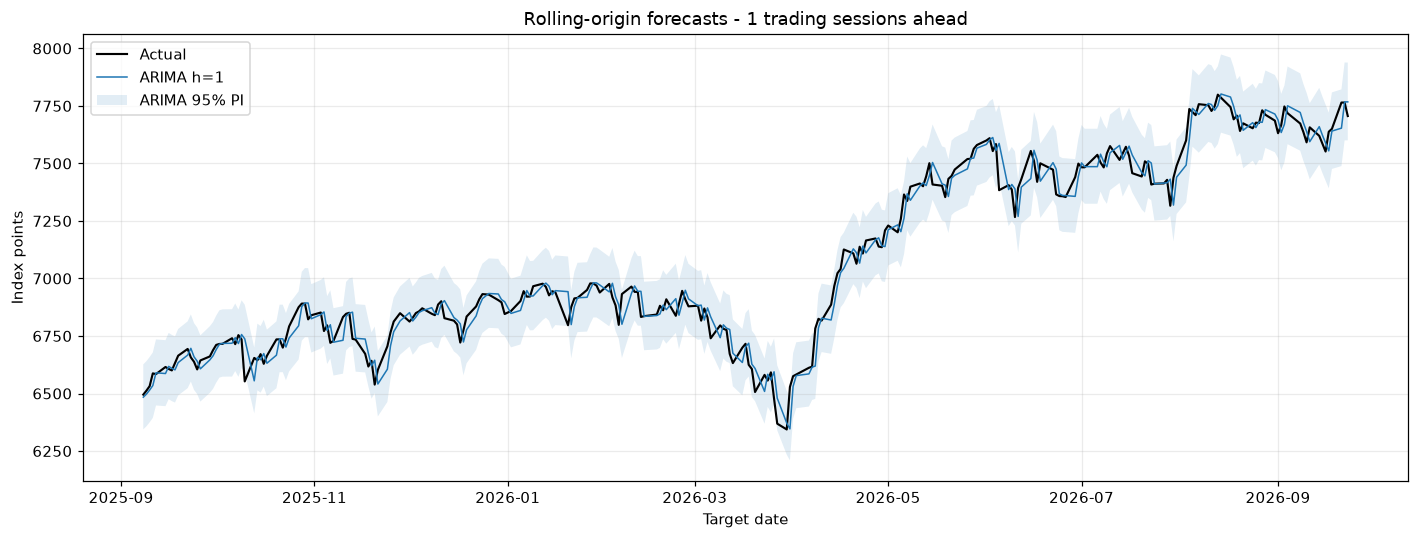

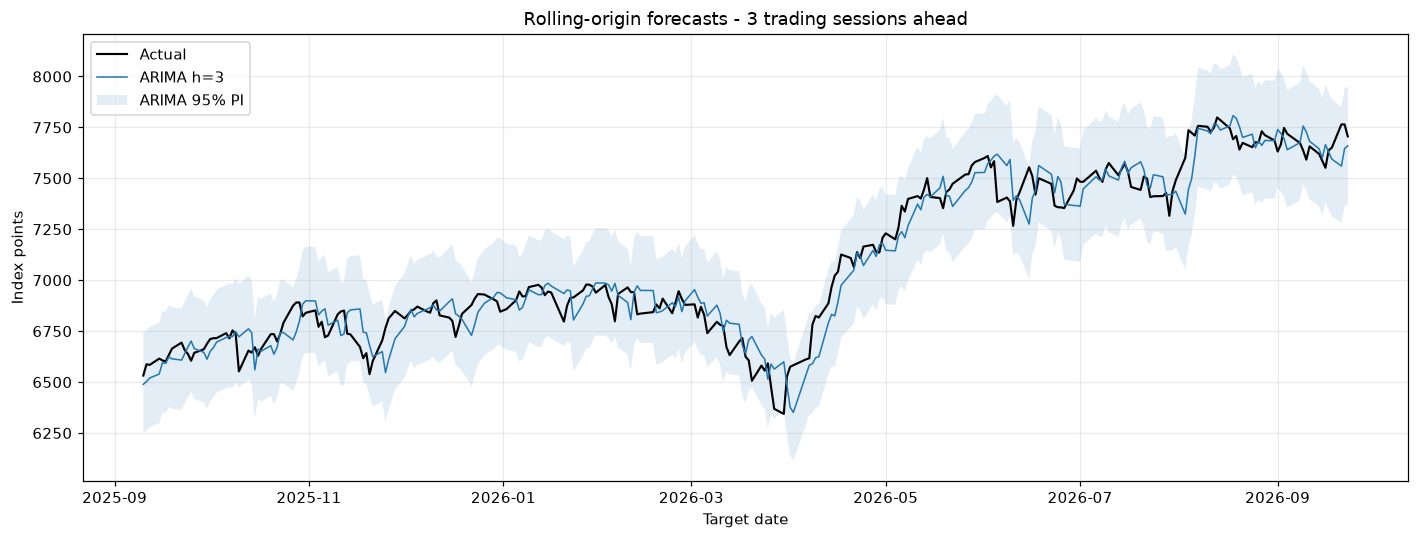

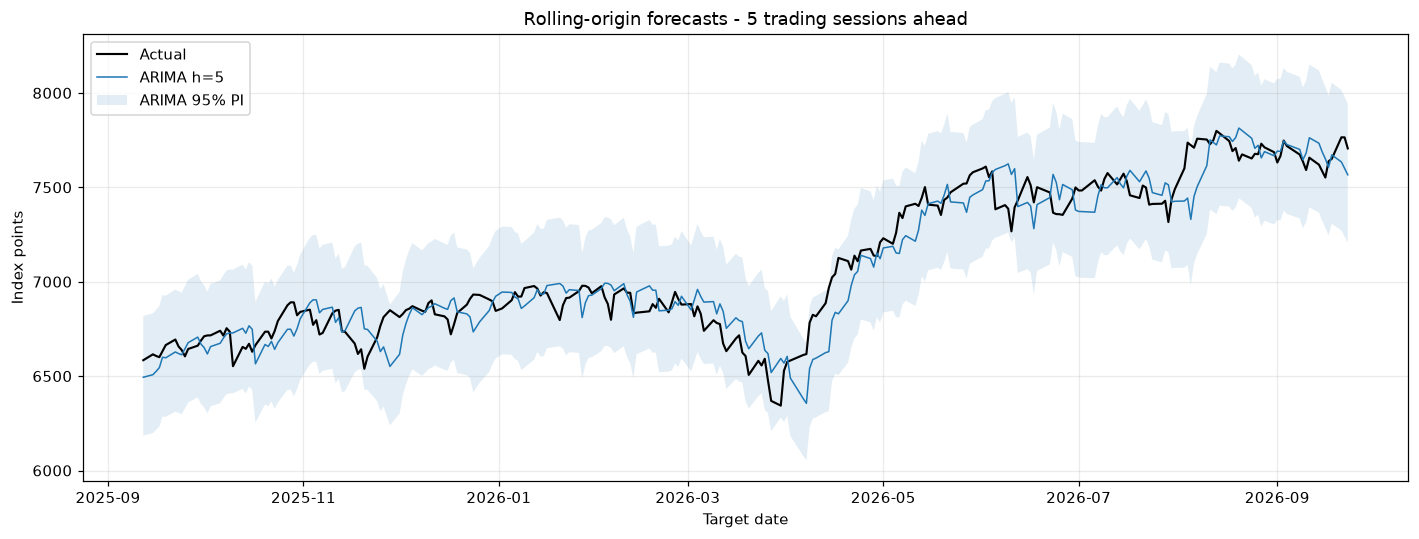

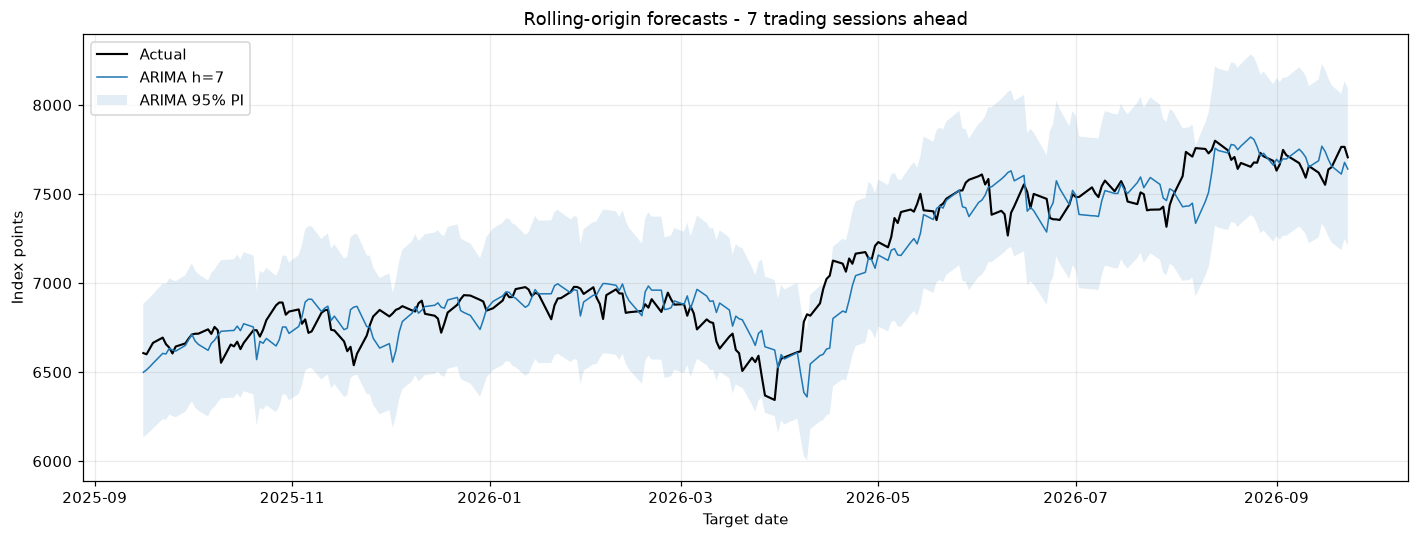

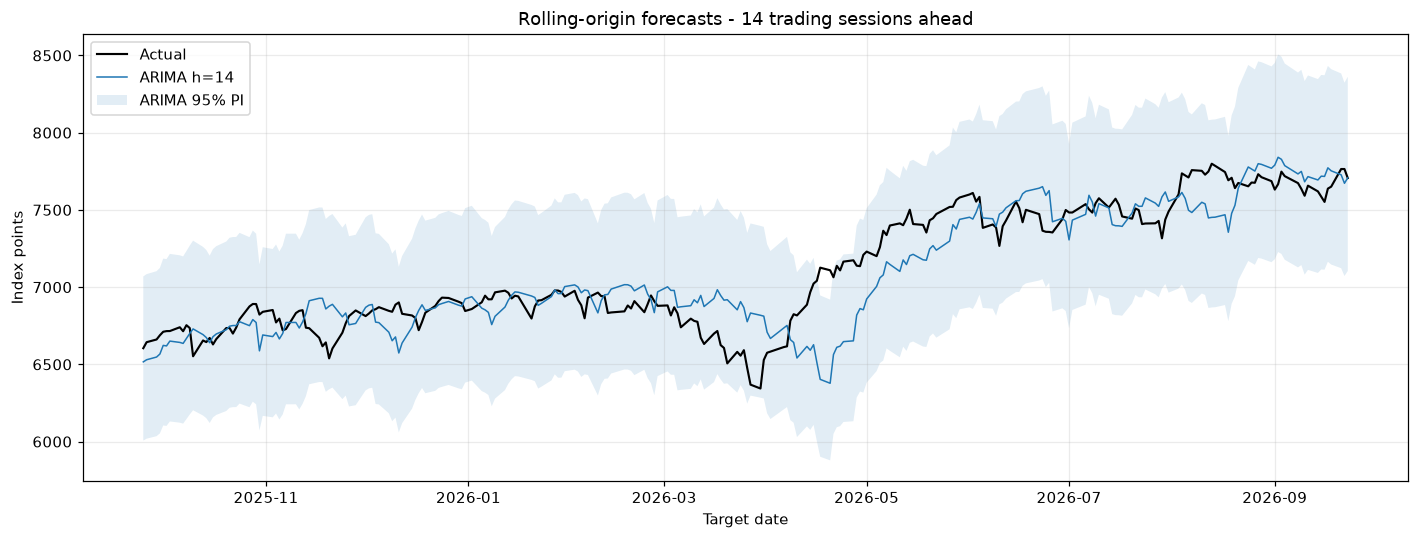

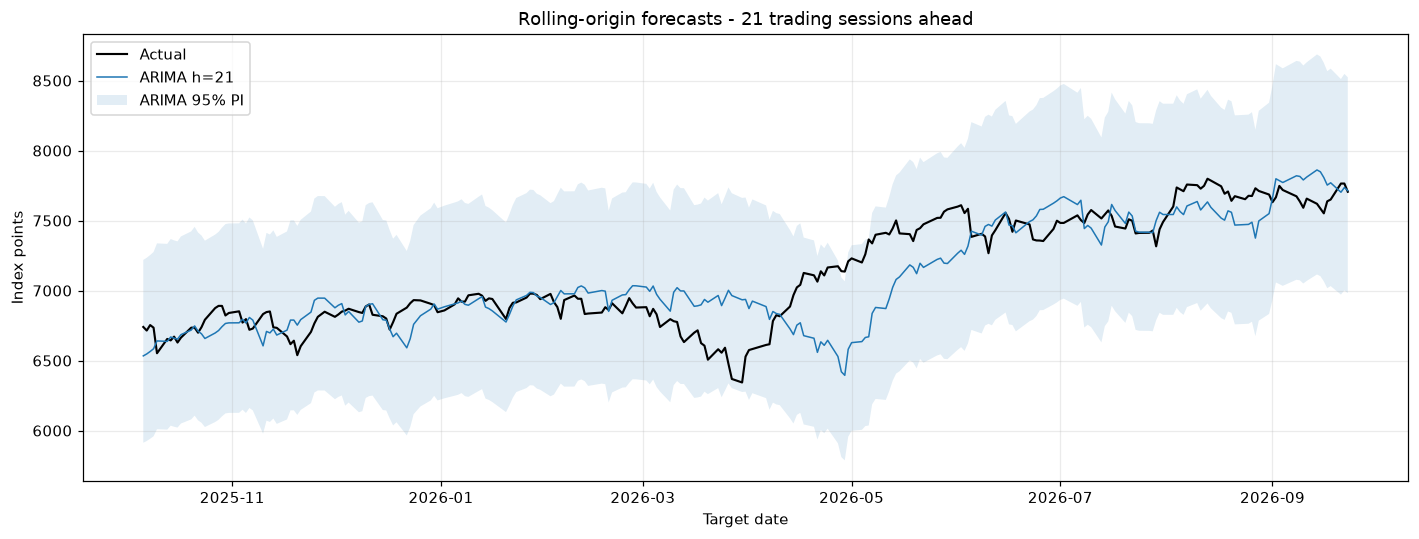

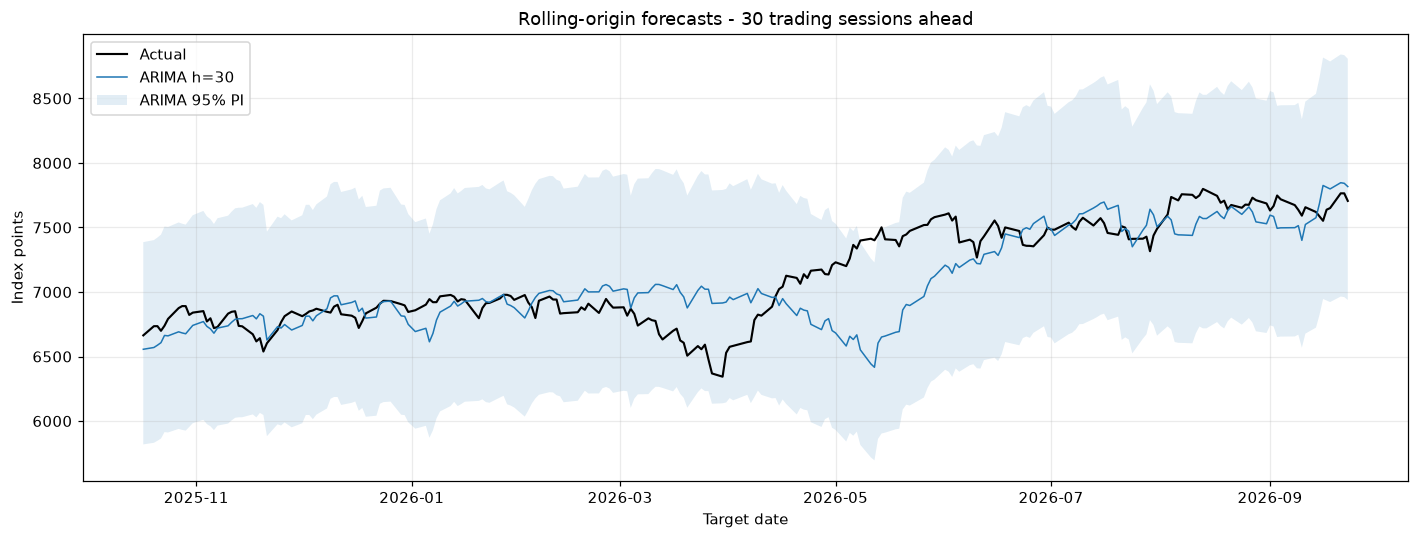

In [14]:
for h, group in forecasts.groupby('h', sort=True):
    fig, ax = plt.subplots(figsize=(13, 5))
    ax.plot(group['target_date'], group['actual'], color='black', label='Actual', linewidth=1.4)
    ax.plot(group['target_date'], group['arima_fc'], label=f'ARIMA h={h}', linewidth=1)
    ax.fill_between(group['target_date'], group['arima_lo95'], group['arima_hi95'], alpha=0.13, label='ARIMA 95% PI')
    ax.set(title=f'Rolling-origin forecasts - {h} trading sessions ahead', xlabel='Target date', ylabel='Index points')
    ax.legend()
    save_figure(fig, f'09_forecast_h{h}.png')


### 8.3 Fixed-origin forecast path from the final Train session

This supplementary plot uses the same Train fit and the first max(horizons) actual Test session dates. It is separate from the rolling-origin metric design.

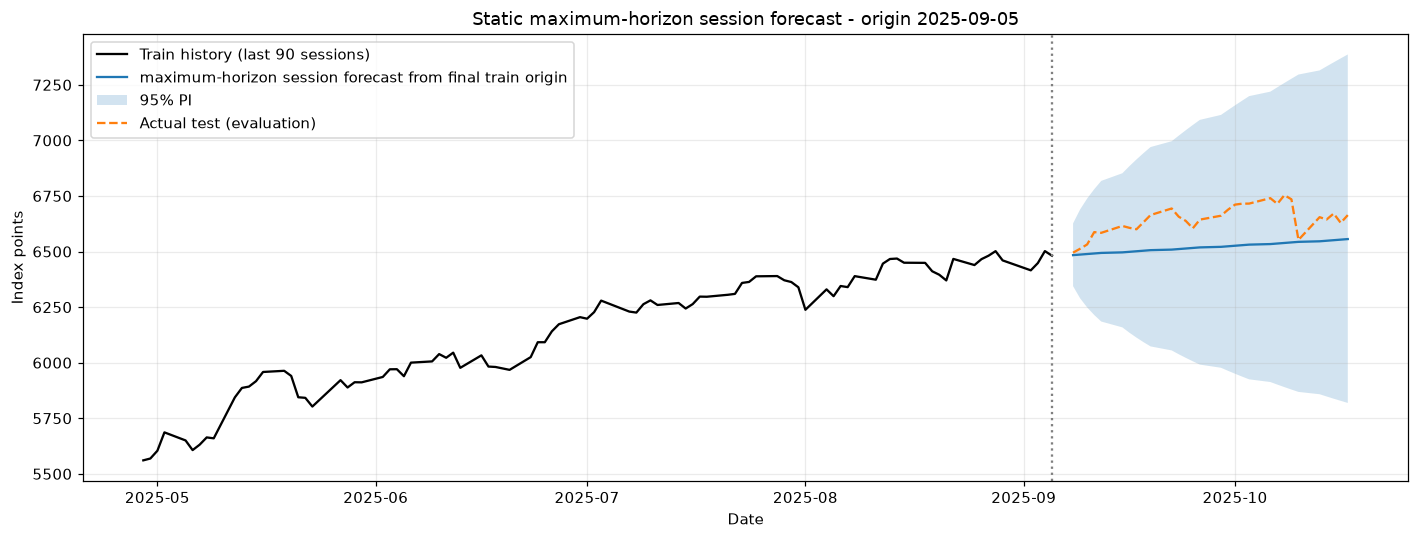

In [15]:
static_fc = res.get_forecast(steps=max(HORIZONS))
static_dates = test_price.index[:max(HORIZONS)]
static_mean = np.exp(np.asarray(static_fc.predicted_mean))
static_ci = np.exp(np.asarray(static_fc.conf_int(alpha=ALPHA)))
save_table(pd.DataFrame(dict(target_date=static_dates, arima_fc=static_mean,
    arima_lo95=static_ci[:, 0], arima_hi95=static_ci[:, 1])), 'static_30d_forecast.csv')
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(train_price.iloc[-90:], color='black', label='Train history (last 90 sessions)')
ax.plot(static_dates, static_mean, label='maximum-horizon session forecast from final train origin')
ax.fill_between(static_dates, static_ci[:, 0], static_ci[:, 1], alpha=0.2, label='95% PI')
ax.plot(test_price.iloc[:max(HORIZONS)], linestyle='--', color='tab:orange', label='Actual test (evaluation)')
ax.axvline(train_price.index[-1], color='gray', linestyle=':')
ax.set(title=f'Static maximum-horizon session forecast - origin {train_price.index[-1].date()}', ylabel='Index points', xlabel='Date')
ax.legend()
save_figure(fig, '10_static_30d_fan.png')


### 8.4 RMSE and MAPE versus horizon (trading sessions)

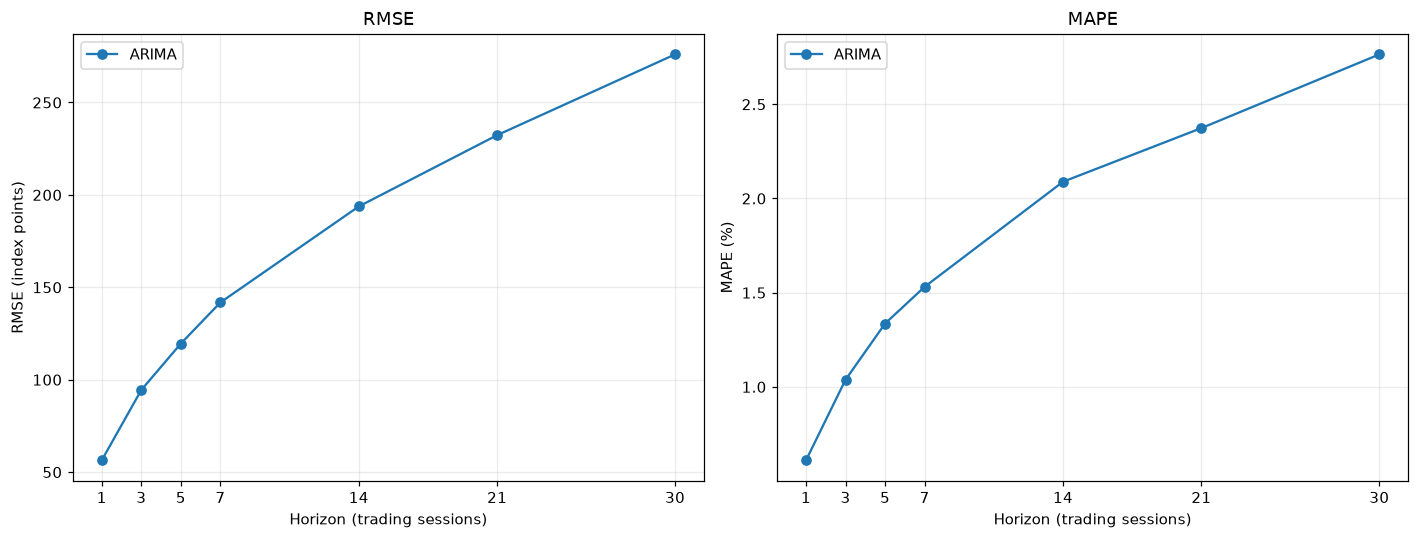

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, metric, unit in zip(axes, ['RMSE', 'MAPE'], ['index points', '%']):
    ax.plot(evaluation['h'], evaluation[metric], marker='o', label='ARIMA')
    ax.set(title=metric, xlabel='Horizon (trading sessions)', ylabel=f'{metric} ({unit})', xticks=HORIZONS)
    ax.legend()
save_figure(fig, '11_error_vs_horizon.png')

## Step 9 - Summary from this execution

Results below are generated from this run, not copied from BTC. Diagnostic evidence, historical Test performance and future forecasts describe different aspects of the model.

In [17]:
lines = ['### S&P 500 ARIMA results', '',
    f'Data: {n:,} NYSE sessions, {df.index[0].date()} to {df.index[-1].date()}.',
    f'Raw Train/Test={n_train}/{n_test}; Train ends {train_price.index[-1].date()}, Test starts {test_price.index[0].date()}.',
    'No validation, cross-validation, Test tuning, early stopping or all-data refit.',
    f'Horizons: {HORIZONS} trading sessions; RMSE units=index points.',
    '', '**Train-only stationarity evidence**']
for row in stationarity_tests.itertuples(index=False):
    lines.append(f'- d={row.d}, {row.test}: statistic={row.statistic:.5g}, p={row.p_value:.5g}; {row.conclusion}.')
lines += ['', f'**Selected model:** {final_label}; AIC={res.aic:.3f}, BIC={res.bic:.3f}.',
    f'Lowest AIC among the top {TOP_K} converged candidates satisfying Train Ljung-Box and root gates.',
    '', '**Train diagnostics (reporting tests do not change selection)**']
for row in assumption_checks.loc[assumption_checks.model.eq(final_label)].itertuples(index=False):
    ptext = f', p={row.p_value:.5g}' if pd.notna(row.p_value) else ''
    lines.append(f'- {row.test}: {row.pass_fail}{ptext}. {row.note}')
lines += ['', '**Historical Test performance**', '',
    '| Horizon (sessions) | Pairs | RMSE (index points) | MAPE (%) |',
    '|---:|---:|---:|---:|']
for row in evaluation.itertuples(index=False):
    lines.append(f'| {row.h} | {row.n_points} | {row.RMSE:,.2f} | {row.MAPE:.2f} |')
lines += ['', '**Future forecasts from the latest observed session**']
for row in future_forecasts.itertuples(index=False):
    lines.append(f'- h={row.h}: origin={row.origin_date.date()}, target={row.target_date.date()}, '
        f'forecast={row.arima_fc:,.2f} points; model 95% PI=[{row.arima_lo95:,.2f}, {row.arima_hi95:,.2f}].')
if (int(final_spec.p), d, int(final_spec.q), final_spec.trend) == (0,1,0,'n'):
    lines += ['', 'ARIMA(0,1,0) without drift gives the latest observed level at every horizon; interval width still grows.']
lines += ['', '**Limitations and interpretation**',
    '- Train fit and passing diagnostics do not establish future accuracy. No independent validation estimate exists.',
    '- ARCH/non-normality can impair model-based interval coverage. Robust parameter standard errors do not model volatility or fix interval coverage.',
    '- Exponentiating the log forecast yields a conditional median, without lognormal mean bias correction.',
    '- RMSE/MAPE describe historical Test targets only; future rows have no observed actuals or error metrics.',
    '- MAPE is an error percentage; 100 minus MAPE is not statistical accuracy.',
    '- Horizon samples differ and errors overlap; observed Test results never revise this model design.',
    '- Univariate index levels do not observe news, policy changes, interest rates, inflation or unexpected market events.',
    '- Source Volume is entirely missing and unused; no prices or volume were imputed.',
    '- Scheduled NYSE sessions are used; unexpected future market closures remain possible.',
    '- Every table/figure and this summary is retained in this existing notebook; no separate artifact files were created.']
lines += ['', '**Daily future forecasts**', 'Tables for 7 and 30 future steps are shown before metrics; dates follow the existing asset calendar convention.']
summary_markdown = '\n'.join(lines)
display(Markdown(summary_markdown))
# Completeness and parameter-freezing audits without fitting anything new.
required_tables = ['library_versions.csv','calendar_audit.csv','split_summary.csv','stationarity_tests.csv',
    'grid_search_aic_bic.csv','top3_candidates.csv','auto_arima_cross_check.csv','assumption_checks.csv',
    'forecasts_long.csv','evaluation_by_horizon.csv','future_forecast_by_horizon.csv',
    *[f'forecasts_h{h}.csv' for h in HORIZONS]]
required_tables += [f'future_forecast_daily_{days}d.csv' for days in DAILY_FORECAST_WINDOWS]
assert all(name in notebook_tables for name in required_tables)
assert np.array_equal(np.asarray(res.params), frozen_params)
assert counts.to_dict() == {h:n_test-h+1 for h in HORIZONS}
assert not len(missing_sessions) and not len(unexpected_dates)
process_audit = pd.DataFrame([dict(check=name,status='PASS') for name in
    ['Chronological raw 80/20 split','NYSE session completeness','Train-only development',
     'Fixed parameters in Test and future inference','Forecast dates/counts/alignment',
     'Separate historical/future tables','Only RMSE/MAPE per horizon','Notebook-only outputs']])
display(process_audit)
print(f'Completed: {len(notebook_tables)} tables retained in memory; {len(notebook_figures)} figures embedded; parameters fixed.')
# Persist all supplementary diagnostic rows as notebook outputs for offline review.
display(Markdown('### Full diagnostic table archive (no external files)'))
for table_name in ['grid_search_aic_bic.csv','parameter_significance.csv','model_roots.csv',
                   'candidate_diagnostics.csv','robust_parameter_significance.csv']:
    if table_name in notebook_tables:
        display(Markdown(f'**{table_name.removesuffix(".csv")}**'))
        show_scroll_table(notebook_tables[table_name])


### S&P 500 ARIMA results

Data: 1,313 NYSE sessions, 2021-07-01 to 2026-09-23.
Raw Train/Test=1050/263; Train ends 2025-09-05, Test starts 2025-09-08.
No validation, cross-validation, Test tuning, early stopping or all-data refit.
Horizons: [1, 3, 5, 7, 14, 21, 30] trading sessions; RMSE units=index points.

**Train-only stationarity evidence**
- d=0, ADF: statistic=-0.37893, p=0.91356; fail to reject nonstationarity.
- d=0, KPSS: statistic=4.032, p=0.01; reject stationarity.
- d=1, ADF: statistic=-19.984, p=0; reject nonstationarity.
- d=1, KPSS: statistic=0.18821, p=0.1; fail to reject stationarity.

**Selected model:** ARIMA(0,1,0), trend=t; AIC=-6459.199, BIC=-6449.288.
Lowest AIC among the top 3 converged candidates satisfying Train Ljung-Box and root gates.

**Train diagnostics (reporting tests do not change selection)**
- Ljung-Box lag 10: PASS, p=0.52754. model_df=0
- Ljung-Box lag 20: PASS, p=0.16156. model_df=0
- Ljung-Box lag 30: PASS, p=0.211. model_df=0
- Mean = 0 (t-test): PASS, p=0.98855. Residual mean=4.92881e-06
- ARCH LM (10 lags): FAIL, p=1.4944e-25. 
- Jarque-Bera: FAIL, p=0. skew=0.0517, kurtosis=9.3495
- AR roots outside unit circle: REPORTED. N/A: no roots
- MA roots outside unit circle: REPORTED. N/A: no roots
- Parameter significance: x1: FAIL, p=0.26553. Report only; estimate in statistic column, significance uses p < alpha
- Parameter significance: sigma2: PASS, p=0. Report only; estimate in statistic column, significance uses p < alpha

**Historical Test performance**

| Horizon (sessions) | Pairs | RMSE (index points) | MAPE (%) |
|---:|---:|---:|---:|
| 1 | 263 | 56.38 | 0.61 |
| 3 | 261 | 94.45 | 1.04 |
| 5 | 259 | 119.53 | 1.34 |
| 7 | 257 | 141.79 | 1.53 |
| 14 | 250 | 193.75 | 2.09 |
| 21 | 243 | 232.33 | 2.37 |
| 30 | 234 | 276.03 | 2.76 |

**Future forecasts from the latest observed session**
- h=1: origin=2026-09-23, target=2026-09-24, forecast=7,708.97 points; model 95% PI=[7,542.93, 7,878.67].
- h=3: origin=2026-09-23, target=2026-09-28, forecast=7,714.86 points; model 95% PI=[7,429.32, 8,011.38].
- h=5: origin=2026-09-23, target=2026-09-30, forecast=7,720.76 points; model 95% PI=[7,353.85, 8,105.97].
- h=7: origin=2026-09-23, target=2026-10-02, forecast=7,726.65 points; model 95% PI=[7,294.11, 8,184.85].
- h=14: origin=2026-09-23, target=2026-10-13, forecast=7,747.33 points; model 95% PI=[7,141.17, 8,404.95].
- h=21: origin=2026-09-23, target=2026-10-22, forecast=7,768.07 points; model 95% PI=[7,030.37, 8,583.18].
- h=30: origin=2026-09-23, target=2026-11-04, forecast=7,794.81 points; model 95% PI=[6,918.48, 8,782.15].

**Limitations and interpretation**
- Train fit and passing diagnostics do not establish future accuracy. No independent validation estimate exists.
- ARCH/non-normality can impair model-based interval coverage. Robust parameter standard errors do not model volatility or fix interval coverage.
- Exponentiating the log forecast yields a conditional median, without lognormal mean bias correction.
- RMSE/MAPE describe historical Test targets only; future rows have no observed actuals or error metrics.
- MAPE is an error percentage; 100 minus MAPE is not statistical accuracy.
- Horizon samples differ and errors overlap; observed Test results never revise this model design.
- Univariate index levels do not observe news, policy changes, interest rates, inflation or unexpected market events.
- Source Volume is entirely missing and unused; no prices or volume were imputed.
- Scheduled NYSE sessions are used; unexpected future market closures remain possible.
- Every table/figure and this summary is retained in this existing notebook; no separate artifact files were created.

**Daily future forecasts**
Tables for 7 and 30 future steps are shown before metrics; dates follow the existing asset calendar convention.

,check,status
0,Chronological raw 80/20 split,PASS
1,NYSE session completeness,PASS
2,Train-only development,PASS
3,Fixed parameters in Test and future inference,PASS
4,Forecast dates/counts/alignment,PASS
5,Separate historical/future tables,PASS
6,Only RMSE/MAPE per horizon,PASS
7,Notebook-only outputs,PASS


Completed: 26 tables retained in memory; 17 figures embedded; parameters fixed.


### Full diagnostic table archive (no external files)

**grid_search_aic_bic**

...

model,kind,root_number,real,imag,modulus,outside
"ARIMA(0,1,3), trend=n",MA,1,2.4538,-0.0000,2.4538,True
"ARIMA(0,1,3), trend=n",MA,2,-1.1989,-2.1632,2.4732,True
"ARIMA(0,1,3), trend=n",MA,3,-1.1989,2.1632,2.4732,True
"ARIMA(3,1,0), trend=n",AR,1,-2.4275,-0.0000,2.4275,True
"ARIMA(3,1,0), trend=n",AR,2,1.2438,-2.1668,2.4985,True
"ARIMA(3,1,0), trend=n",AR,3,1.2438,2.1668,2.4985,True


**candidate_diagnostics**

model,AIC,ljung_box_pass,roots_pass,arch_pvalue
"ARIMA(0,1,0), trend=t","-6,459.1987",True,True,0.0000
"ARIMA(0,1,3), trend=n","-6,458.8840",True,True,0.0000
"ARIMA(3,1,0), trend=n","-6,458.7261",True,True,0.0000


**robust_parameter_significance**

model,parameter,estimate,robust_standard_error,robust_p_value,converged,warnings
"ARIMA(0,1,0), trend=t",x1,0.0004,0.0003,0.2658,True,
"ARIMA(0,1,0), trend=t",sigma2,0.0001,0.0000,0.0000,True,
"ARIMA(0,1,3), trend=n",ma.L1,-0.0155,0.0478,0.7454,True,
"ARIMA(0,1,3), trend=n",ma.L2,0.0037,0.0366,0.9187,True,
"ARIMA(0,1,3), trend=n",ma.L3,-0.0666,0.0562,0.2362,True,
"ARIMA(0,1,3), trend=n",sigma2,0.0001,0.0000,0.0000,True,
"ARIMA(3,1,0), trend=n",ar.L1,-0.0134,0.0482,0.7803,True,
"ARIMA(3,1,0), trend=n",ar.L2,0.0040,0.0363,0.9128,True,
"ARIMA(3,1,0), trend=n",ar.L3,-0.0660,0.0558,0.2372,True,
"ARIMA(3,1,0), trend=n",sigma2,0.0001,0.0000,0.0000,True,


## Method references

- [statsmodels ARIMA](https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima.model.ARIMA.html)
- [ARIMAResults.apply with fixed parameters](https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima.model.ARIMAResults.apply.html)
- [pmdarima auto_arima](https://alkaline-ml.com/pmdarima/modules/generated/pmdarima.arima.auto_arima.html)
- [NYSE holidays and trading hours](https://www.nyse.com/trade/hours-calendars)
- [NYSE special closure, 9 January 2025](https://www.nyse.com/publicdocs/nyse/markets/american-options/rule-interpretations/2025/National_Day_of_Mourning_20250102.pdf)